# Laboratorio 7 — NLP end-to-end y Embeddings
**CC3092 · Deep Learning y Sistemas Inteligentes**

Pipeline completo: texto crudo → tokens → IDs → embeddings (SGNS propio en PyTorch, Word2Vec de gensim, GloVe preentrenado) → evaluación (analogías, similitud) → clasificación de AG News.

**Convenciones del notebook**
- Todo lo costoso se guarda en `artifacts/` (caché). Si el archivo existe, se carga en vez de recalcular.
- Para la **selección de configuraciones** solo se usan WordSim-353 y `questions-words.txt`. **SimLex-999 se reserva** para la evaluación final (sección 6/7).
- Subconjunto de WikiText-103 usado para entrenar: primeras ~30 M de tokens (el enunciado exige ≥ 20 M), el mismo para SGNS y gensim.

In [1]:
import os, re, json, time, math, html, pickle, random, collections, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch, torch.nn as nn, torch.nn.functional as F
from tqdm.auto import tqdm

warnings.filterwarnings("ignore")
SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED); torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
ART = Path("artifacts"); ART.mkdir(exist_ok=True)
VEC = Path("vectors"); VEC.mkdir(exist_ok=True)
FIG = Path("figures"); FIG.mkdir(exist_ok=True)
SUBSET_TOKENS = 30_000_000          # tamaño objetivo del subconjunto de entrenamiento
print("device:", DEVICE, "|", torch.cuda.get_device_name(0) if DEVICE.type == "cuda" else "cpu")
print("torch", torch.__version__)

device: cuda | NVIDIA GeForce GTX 1660 SUPER
torch 2.13.0+cu126


## 2. Exploración y preprocesamiento del texto

### 2.1 Carga de datos y estadísticas básicas

In [2]:
from datasets import load_dataset
import gensim.downloader as api

wiki = load_dataset("Salesforce/wikitext", "wikitext-103-raw-v1")
news = load_dataset("fancyzhx/ag_news")
train_lines = wiki["train"]["text"]            # 1.8 M líneas (párrafos, encabezados y líneas vacías)
print({k: len(v) for k, v in wiki.items()}, "| AG News:", {k: len(v) for k, v in news.items()})

{'test': 4358, 'train': 1801350, 'validation': 3760} | AG News: {'train': 120000, 'test': 7600}


### 2.2 Normalización y tokenizador propio

**Decisiones (y por qué):**

| Aspecto | Decisión | Justificación |
|---|---|---|
| Mayúsculas | todo a minúsculas | GloVe (`glove-wiki-gigaword-100`) es *uncased*; si no, `The` y `the` serían palabras distintas en nuestro vocabulario pero la misma en GloVe y la comparación no sería justa. |
| Marcadores de WikiText | `@-@`, `@,@`, `@.@` se **reunen** (`role @-@ playing` → `role-playing`, `1 @,@ 000` → `1,000`) | Son artefactos del dataset; GloVe sí tiene `role-playing` y `1,000` como tokens. |
| Puntuación | cada signo es un token independiente (`,` `.` `"` …) | GloVe también trata la puntuación como tokens; así las coberturas son comparables. |
| Números | **se conservan** tal cual (`1,000`, `3.5`, `2010`) | GloVe conserva los números; mapearlos a `<num>` rompería la correspondencia con su vocabulario. |
| Contracciones | estilo PTB como el de GloVe: `don't → do n't`, `it's → it 's` | Es la convención de Stanford (Wikipedia + Gigaword); WikiText ya trae `'s` separado. |
| Encabezados (` = Título = `) | se **descartan** del entrenamiento (se cuentan en las estadísticas) | No son oraciones; contaminarían las ventanas de contexto. |
| Tokens especiales | no se usan en SGNS (las palabras raras se **eliminan** como en word2vec). Para clasificación se usa `<unk>`/`<pad>` | Reemplazar raras por `<unk>` crearía un "supertoken" muy frecuente con contextos arbitrarios. |
| Artefactos de AG News | `\` → espacio, entidades HTML (`&lt;`) → carácter | Es ruido propio del dataset. |

El mismo `tokenize()` se aplica a WikiText, a AG News y (en la sección 6) a todo lo que entra al clasificador.

In [3]:
# ---------------- Normalización + tokenizador propio ----------------
_WIKI_AT   = re.compile(r" @([-,.])@ ")                               # "role @-@ playing" -> "role-playing"
_NT        = re.compile(r"(\w)n't\b")                                  # don't -> do n't
_CLITIC    = re.compile(r"(\w)('s|'re|'ve|'ll|'d|'m)\b")               # it's  -> it 's
_TOKEN     = re.compile(r"n't|'(?:s|re|ve|ll|d|m)\b|\d+(?:[.,]\d+)*(?![^\W_])|[^\W_]+(?:-[^\W_]+)*|\S")

def normalize(text: str) -> str:
    text = html.unescape(text).replace("\\", " ").lower()
    text = _WIKI_AT.sub(r"\1", text)
    text = _NT.sub(r"\1 n't", text)
    text = _CLITIC.sub(r"\1 \2", text)
    return text

def tokenize(text: str) -> list:
    return _TOKEN.findall(normalize(text))

print(tokenize("The U.S. didn't spend $1,000 on role @-@ playing games; it's 3.5% of well-known 'Wall St.' data."))

['the', 'u', '.', 's', '.', 'did', "n't", 'spend', '$', '1,000', 'on', 'role-playing', 'games', ';', 'it', "'s", '3.5', '%', 'of', 'well-known', "'", 'wall', 'st', '.', "'", 'data', '.']


### 2.3 Comparación con NLTK (12 oraciones)
Se comparan los tokens (en minúsculas) de nuestro tokenizador contra `nltk.word_tokenize`. Se muestran solo los tokens que difieren.

In [4]:
import nltk
from nltk.tokenize import word_tokenize
try: word_tokenize("test")
except LookupError: nltk.download("punkt_tab", quiet=True)

sents = [
    "I can't believe it's already 2026, isn't it?",
    "She said: \"Don't go!\" and left.",
    "The state-of-the-art model costs $1,250.50 per month.",
    "Dr. Smith works at the U.S. Department of Energy.",
    "They're well-known for their mother-in-law's cooking.",
    "We'll meet at 5:30 p.m. on Jan. 5th, okay?",
    "O'Brien's e-mail is john.doe@example.com.",
    "It's a 3-1 win; the score was 3.5 to 2.",
    "Wouldn't you've known? That's rock 'n' roll!",
    "COVID-19 cases rose 12% in New York (N.Y.) yesterday.",
    "The anti-virus wasn't updated, so e.g. spam got through.",
    "Prices rose from $1,000 to 1,500 euros -- a 50% jump.",
]
rows = []
for s in sents:
    mine, ref = tokenize(s), [t.lower() for t in word_tokenize(s)]
    only_m = [t for t in mine if t not in ref]; only_n = [t for t in ref if t not in mine]
    rows.append({"oración": s, "solo_mío": only_m, "solo_nltk": only_n, "igual": mine == ref})
cmp_df = pd.DataFrame(rows)
pd.set_option("display.max_colwidth", 80, "display.width", 220)
display(cmp_df)
print(f"Coinciden exactamente: {cmp_df['igual'].sum()}/{len(cmp_df)}")

,oración,solo_mío,solo_nltk,igual
0,"I can't believe it's already 2026, isn't it?",[],[],True
1,"She said: ""Don't go!"" and left.","["", ""]","[``, '']",False
2,"The state-of-the-art model costs $1,250.50 per month.",[],[],True
3,Dr. Smith works at the U.S. Department of Energy.,"[dr, u, s]","[dr., u.s.]",False
4,They're well-known for their mother-in-law's cooking.,[],[],True
5,"We'll meet at 5:30 p.m. on Jan. 5th, okay?","[5, :, 30, p, ., m, ., jan, .]","[5:30, p.m., jan.]",False
6,O'Brien's e-mail is john.doe@example.com.,"[o, ', brien, john, doe, example, com]","[o'brien, john.doe, example.com]",False
7,It's a 3-1 win; the score was 3.5 to 2.,"[3, -, 1]",[3-1],False
8,Wouldn't you've known? That's rock 'n' roll!,[n],['n],False
9,COVID-19 cases rose 12% in New York (N.Y.) yesterday.,"[n, y]",[n.y.],False


Coinciden exactamente: 3/12


**Resultado: coinciden exactamente en 3 de las 12 oraciones.** Coinciden en contracciones (`can't → ca n't`, `it's → it 's`, `isn't → is n't`), compuestos con guion (`state-of-the-art`, `mother-in-law`), y moneda/números (`$1,250.50`). Difieren en:
- **Abreviaturas con punto** (`Dr.`, `U.S.`, `p.m.`, `Jan.`, `N.Y.`, `e.g.`): NLTK las deja como un token (`dr.`, `u.s.`, `p.m.`); nuestro tokenizador las parte en letras y puntos (`u . s .`) porque una regla simple no distingue "punto de abreviatura" de "punto final". Es su principal debilidad: genera tokens ruidosos (`u`, `s`).
- **Comillas:** NLTK usa la convención Treebank (` `` ` y `''`); nosotros dejamos `"` como GloVe.
- **Números con separadores:** `5:30` y `3-1` son un token en NLTK; nosotros los partimos (`5 : 30`, `3 - 1`). Igual `--` (NLTK: un token; nosotros: dos `-`).
- **Apóstrofos internos:** `O'Brien` → NLTK un token; nosotros `o ' brien`. En `'n'`, NLTK da `'n`, nosotros `n`.
- **e-mails/URL:** NLTK separa solo parcialmente (`john.doe`, `example.com`); nosotros fragmentamos todo (`john doe example com`).

Para un corpus de ~100 M de tokens estas diferencias afectan a una fracción pequeña de los tokens; lo importante es que el **mismo** tokenizador se use en el corpus, en AG News y al consultar benchmarks.

### 2.4 Tokenización de todo el corpus: tokens, líneas y artículos
Un solo pase sobre las 1.8 M líneas: se cuenta la frecuencia de cada palabra (corpus **completo**) y se guardan los IDs del **subconjunto** de entrenamiento (primeras ~30 M de tokens). Se cachea en `artifacts/`.

In [5]:
HEAD_RE    = re.compile(r"^\s*=+ .* =+\s*$")          # encabezados " = X = ", " = = Y = = "
ARTICLE_RE = re.compile(r"^ = [^=].* = \n?$")          # solo nivel 1 => un artículo

stats_path, counts_path = ART / "corpus_stats.json", ART / "counts_full.pkl"
sub_ids_path, sub_len_path, vocab_path = ART / "sub_ids_dyn.npy", ART / "sub_line_len_dyn.npy", ART / "sub_vocab_dyn.json"

if not (stats_path.exists() and counts_path.exists() and sub_ids_path.exists()):
    t0 = time.time()
    counts = collections.Counter()
    dyn = {}                                  # palabra -> id dinámico (solo para el subconjunto)
    sub_ids, sub_len = [], []
    n_lines = n_empty = n_head = n_articles = n_tokens = 0
    in_subset = True
    for line in tqdm(train_lines, desc="tokenizando"):
        n_lines += 1
        if not line.strip(): n_empty += 1; continue
        if HEAD_RE.match(line):
            n_head += 1; n_articles += bool(ARTICLE_RE.match(line)); continue
        toks = tokenize(line)
        if not toks: continue
        counts.update(toks); n_tokens += len(toks)
        if in_subset:
            sub_ids.extend(dyn.setdefault(w, len(dyn)) for w in toks)
            sub_len.append(len(toks))
            if n_tokens >= SUBSET_TOKENS: in_subset = False
    stats = dict(n_lines=n_lines, n_empty=n_empty, n_headings=n_head, n_articles=n_articles,
                 n_text_lines=n_lines - n_empty - n_head, n_tokens=n_tokens, n_types=len(counts),
                 subset_tokens=len(sub_ids), subset_lines=len(sub_len), secs=time.time() - t0)
    np.save(sub_ids_path, np.asarray(sub_ids, dtype=np.int32)); np.save(sub_len_path, np.asarray(sub_len, dtype=np.int32))
    json.dump([w for w, _ in sorted(dyn.items(), key=lambda kv: kv[1])], open(vocab_path, "w", encoding="utf-8"))
    pickle.dump(dict(counts), open(counts_path, "wb")); json.dump(stats, open(stats_path, "w"), indent=1)

stats = json.load(open(stats_path)); counts_full = pickle.load(open(counts_path, "rb"))
print(json.dumps(stats, indent=1))

{
 "n_lines": 1801350,
 "n_empty": 636321,
 "n_headings": 305074,
 "n_articles": 29444,
 "n_text_lines": 859955,
 "n_tokens": 97490132,
 "n_types": 702400,
 "subset_tokens": 30000154,
 "subset_lines": 265874,
 "secs": 118.1724112033844
}


### 2.5 Ley de Zipf
Frecuencia vs. rango en escala log-log, y cobertura acumulada de las palabras más frecuentes.

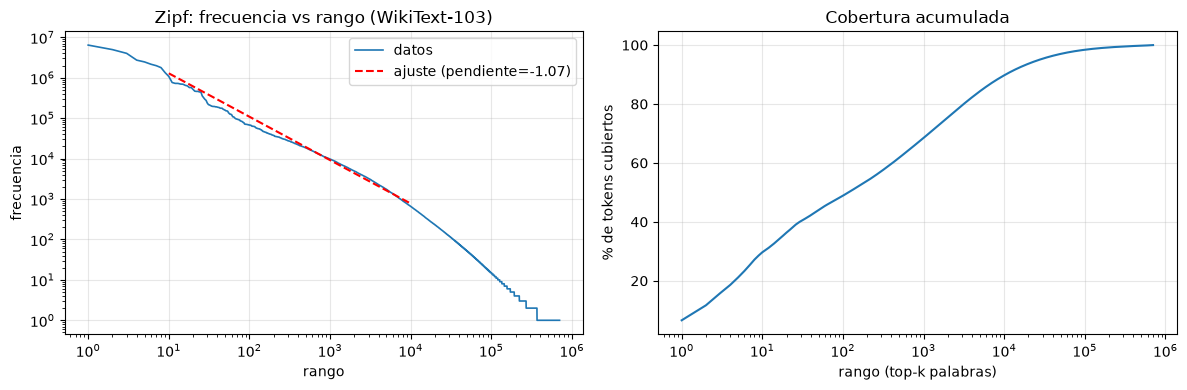

Pendiente log-log (rangos 10-10 000): -1.073  (Zipf ideal ≈ -1)
  top     10 palabras cubren 29.67% de los tokens
  top  1,000 palabras cubren 68.48% de los tokens
  top 30,000 palabras cubren 95.39% de los tokens


In [6]:
freqs = np.sort(np.fromiter(counts_full.values(), dtype=np.int64))[::-1]
ranks = np.arange(1, len(freqs) + 1); total = freqs.sum()

# Ajuste de la pendiente en el tramo central (rangos 10 .. 10 000), donde Zipf suele valer
sl = slice(9, 10_000)
slope, intercept = np.polyfit(np.log(ranks[sl]), np.log(freqs[sl]), 1)

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].loglog(ranks, freqs, lw=1.2, label="datos")
ax[0].loglog(ranks[sl], np.exp(intercept) * ranks[sl] ** slope, "r--", label=f"ajuste (pendiente={slope:.2f})")
ax[0].set(xlabel="rango", ylabel="frecuencia", title="Zipf: frecuencia vs rango (WikiText-103)"); ax[0].legend(); ax[0].grid(alpha=.3)
ax[1].semilogx(ranks, np.cumsum(freqs) / total * 100)
ax[1].set(xlabel="rango (top-k palabras)", ylabel="% de tokens cubiertos", title="Cobertura acumulada"); ax[1].grid(alpha=.3)
plt.tight_layout(); plt.show()

cov = {k: freqs[:k].sum() / total * 100 for k in (10, 1_000, 30_000)}
print("Pendiente log-log (rangos 10-10 000): %.3f  (Zipf ideal ≈ -1)" % slope)
for k, v in cov.items(): print(f"  top {k:>6,} palabras cubren {v:5.2f}% de los tokens")

**Lectura:** en el tramo central (rangos 10–10 000) la curva es casi una recta en log-log con pendiente **−1.07**, así que **la ley de Zipf se cumple aproximadamente**; se desvía en los extremos (la cola de palabras con frecuencia 1, 2, 3… forma "escalones"). El corpus tiene **97.5 M de tokens, 702 k tipos distintos, 29 444 artículos y 859 955 líneas de texto** (además de 636 k líneas vacías y 305 k encabezados descartados). Las **10 palabras más frecuentes cubren el 29.7 %** de los tokens, **las 1 000 más frecuentes el 68.5 %** y **las 30 000 más frecuentes el 95.4 %**: pocas palabras concentran casi todo el texto, lo que justifica el submuestreo de las frecuentes y el corte por `min_count`. (El total es menor que las ~103 M de tokens "oficiales" de WikiText-103 en parte porque aquí se unen los marcadores `@-@`/`@,@` y se descartan los encabezados.)

### 2.6 Vocabulario con umbral de frecuencia mínima (`min_count`)
Tamaño de vocabulario y % de tokens desconocidos (tokens cuya palabra queda por debajo del umbral) sobre el corpus completo.

In [7]:
rows = []
for mc in (1, 2, 3, 5, 10, 20, 50, 100):
    keep = freqs >= mc
    rows.append({"min_count": mc, "|V|": int(keep.sum()), "tokens cubiertos %": freqs[keep].sum() / total * 100,
                 "tokens desconocidos %": freqs[~keep].sum() / total * 100})
mc_df = pd.DataFrame(rows); display(mc_df.style.format({"tokens cubiertos %": "{:.3f}", "tokens desconocidos %": "{:.3f}", "|V|": "{:,}"}))

,min_count,|V|,tokens cubiertos %,tokens desconocidos %
0,1,"702,400",100.000,0.000
1,2,"368,144",99.657,0.343
2,3,"269,785",99.455,0.545
3,5,"192,263",99.186,0.814
4,10,"126,918",98.748,1.252
5,20,"85,727",98.173,1.827
6,50,"51,261",97.072,2.928
7,100,"33,820",95.819,4.181


**Lectura (corpus completo):** el vocabulario sin filtro es enorme (702 k tipos, probablemente inflado por números, compuestos con guion y palabras no latinas que el tokenizador conserva). Con `min_count=5` baja a **192 k** (−73 %) y solo el **0.81 %** de los tokens pasa a ser desconocido; con 50 queda en 51 k (2.9 % desconocidos) y con 100 en 33.8 k (4.2 %). Palabras con < 5 ocurrencias no tienen contextos suficientes para aprender un vector fiable, por eso se usa **`min_count = 5`**. Sobre el subconjunto de entrenamiento (primeros ~30 M de tokens) esto da |V| = **100 844** palabras y se descarta el 1.32 % de los tokens.

### 2.7 Vocabulario de entrenamiento, subconjunto y subsampling
Se construye el vocabulario **desde el subconjunto de ~30 M tokens** (`min_count=5`), ordenado por frecuencia (ID 0 = palabra más frecuente). Las palabras raras se eliminan del flujo, como hace word2vec.

In [8]:
MIN_COUNT = 5
dyn_words = json.load(open(vocab_path, encoding="utf-8"))
dyn_ids   = np.load(sub_ids_path); dyn_len = np.load(sub_len_path)
dyn_counts = np.bincount(dyn_ids, minlength=len(dyn_words))

order = [i for i in np.argsort(-dyn_counts, kind="stable") if dyn_counts[i] >= MIN_COUNT]
words = [dyn_words[i] for i in order]                      # vocabulario ordenado por frecuencia
counts = dyn_counts[order].astype(np.int64)
remap = np.full(len(dyn_words), -1, dtype=np.int32); remap[order] = np.arange(len(order), dtype=np.int32)
w2i = {w: i for i, w in enumerate(words)}

new = remap[dyn_ids]; keep = new >= 0
line_of_tok = np.repeat(np.arange(len(dyn_len)), dyn_len)
train_ids = new[keep]                                       # flujo de IDs sin raras
line_len  = np.bincount(line_of_tok[keep], minlength=len(dyn_len)).astype(np.int64)
line_len  = line_len[line_len > 0]
V = len(words); N_TOK = len(train_ids)
print(f"Subconjunto: {N_TOK:,} tokens en {len(line_len):,} líneas | |V|={V:,} (min_count={MIN_COUNT}) | descartados por raros: {(~keep).mean()*100:.2f}%")
print("top-15:", words[:15])

Subconjunto: 29,604,250 tokens en 265,675 líneas | |V|=100,844 (min_count=5) | descartados por raros: 1.32%
top-15: ['the', ',', '.', 'of', 'and', 'in', 'to', 'a', '"', 'was', 'on', 'as', "'s", 'for', 'that']


#### Submuestreo (subsampling) de palabras frecuentes (Mikolov et al.)
Cada ocurrencia de la palabra $w$ con frecuencia relativa $f(w)$ se **conserva** con probabilidad
$$P_{keep}(w)=\min\!\Big(1,\ \big(\sqrt{f(w)/t}+1\big)\,\frac{t}{f(w)}\Big)$$
con umbral $t$ (hiperparámetro). Las palabras muy frecuentes (*the, of, and, ,, .*) aportan poca información sobre su contexto y generan la mayoría de los pares de entrenamiento; descartarlas **acelera el entrenamiento** y deja más peso relativo a las palabras raras/informativas, lo que **mejora la calidad** de sus vectores.

In [9]:
# (Los porcentajes de descarte son teóricos y empíricos; coinciden.)
def keep_prob(counts, t):
    f = counts / counts.sum()
    return np.minimum(1.0, (np.sqrt(f / t) + 1) * t / f)

rng = np.random.default_rng(SEED)
rows = []
for t in (1e-3, 1e-4, 1e-5):
    kp = keep_prob(counts, t)
    sampled = rng.random(N_TOK) < kp[train_ids]
    row = {"t": t, "tokens que sobreviven %": sampled.mean() * 100}
    for w in ("the", "of", "and"):
        row[f"'{w}' descartado %"] = (1 - kp[w2i[w]]) * 100          # probabilidad teórica
        m = train_ids == w2i[w]; row[f"'{w}' (empírico) %"] = (~sampled[m]).mean() * 100
    rows.append(row)
display(pd.DataFrame(rows).style.format({c: "{:.2f}" for c in pd.DataFrame(rows).columns if c != "t"}))

,t,tokens que sobreviven %,'the' descartado %,'the' (empírico) %,'of' descartado %,'of' (empírico) %,'and' descartado %,'and' (empírico) %
0,0.001000,72.09,86.24,86.21,77.73,77.74,76.33,76.38
1,0.000100,54.63,95.97,95.96,93.72,93.69,93.36,93.36
2,0.000010,32.76,98.76,98.76,98.09,98.11,97.98,97.96


**Resultado:** con $t=10^{-4}$ se descarta el **96.0 %** de las apariciones de *"the"*, el **93.7 %** de *"of"* y el **93.4 %** de *"and"* (con $t=10^{-3}$: 86.2 %, 77.7 %, 76.3 %; con $t=10^{-5}$: 98.8 %, 98.1 %, 98.0 %), y sobrevive el 54.6 % de los tokens totales. Los valores empíricos coinciden con la fórmula.

### 2.8 Pares (centro, contexto) del skip-gram
Con ventana $W$ (fija = máxima), cada posición genera hasta $2W$ pares; los pares **no cruzan líneas** (párrafos). Para una línea de longitud $L>W$ el total exacto es $2(LW-W(W+1)/2)$ y $L(L-1)$ si $L\le W$. Se reporta por epoch antes y después del submuestreo (con ventana dinámica de word2vec el promedio real es ≈ $(W+1)/2$ por lado).

In [10]:
def n_pairs(lens, W):
    lens = lens.astype(np.int64)
    return int(np.where(lens > W, 2 * (lens * W - W * (W + 1) // 2), lens * (lens - 1)).sum())

def sub_line_lens(t, rng):
    kp = keep_prob(counts, t); m = rng.random(N_TOK) < kp[train_ids]
    line_idx = np.repeat(np.arange(len(line_len)), line_len)
    return np.bincount(line_idx[m], minlength=len(line_len)), m.sum()

rows = []
for W in (2, 5, 10):
    row = {"ventana W": W, "pares/epoch (sin subsampling)": n_pairs(line_len, W)}
    for t in (1e-3, 1e-4, 1e-5):
        sl_, kept = sub_line_lens(t, np.random.default_rng(SEED)); row[f"t={t:g}"] = n_pairs(sl_, W)
    rows.append(row)
pairs_df = pd.DataFrame(rows); display(pairs_df.style.format({c: "{:,}" for c in pairs_df.columns if c != "ventana W"}))

,ventana W,pares/epoch (sin subsampling),t=0.001,t=0.0001,t=1e-05
0,2,"116,826,338","83,778,744","63,108,924","37,221,106"
1,5,"288,155,324","205,553,752","153,913,714","89,311,294"
2,10,"563,619,940","398,576,590","295,519,812","166,800,892"


**Resultado (ventana fija $W=5$, 29.6 M tokens):** el corpus produce **288.2 M pares por epoch sin submuestreo**; con submuestreo baja a **205.6 M** ($t=10^{-3}$), **153.9 M** ($t=10^{-4}$, −46.6 %) y **89.3 M** ($t=10^{-5}$, −69 %). Con la ventana dinámica de word2vec (radio aleatorio en $1..W$) el número efectivo de pares es ≈ 60 % del de la ventana fija. El submuestreo reduce el trabajo por epoch casi a la mitad sin perder las palabras informativas.

## 3. Investigación: embeddings en PyTorch y gensim
La investigación completa (`nn.Embedding`, `from_pretrained`, `nn.EmbeddingBag`, CBOW vs. skip-gram, las dos matrices de Word2Vec y Word2Vec vs. GloVe) está redactada en el **informe** (`informe/informe.tex`, sección 2). Aquí solo se deja una demostración ejecutable de `nn.EmbeddingBag` con `offsets` y sus tres modos de agregación.

In [11]:
# Demostración de EmbeddingBag con offsets: 3 documentos de longitudes 3, 2 y 1
bag_vals = torch.arange(12, dtype=torch.float).view(6, 2)       # filas [0,1],[2,3],...,[10,11]
flat    = torch.tensor([0, 1, 2,   3, 4,   5])                   # IDs de los 3 documentos concatenados
offsets = torch.tensor([0, 3, 5])                                # posición de inicio de cada documento
for mode in ("mean", "sum", "max"):
    bag = nn.EmbeddingBag.from_pretrained(bag_vals, mode=mode, freeze=True)
    print(mode, "\n", bag(flat, offsets))
print("comprobación manual del 'mean' del primer documento:", bag_vals[[0, 1, 2]].mean(0))

mean 
 tensor([[ 2.,  3.],
        [ 7.,  8.],
        [10., 11.]])
sum 
 tensor([[ 6.,  9.],
        [14., 16.],
        [10., 11.]])
max 
 tensor([[ 4.,  5.],
        [ 8.,  9.],
        [10., 11.]])
comprobación manual del 'mean' del primer documento: tensor([2., 3.])


## 4. Construcción y entrenamiento de los embeddings

### 4.1 Utilidades de evaluación (benchmarks de gensim)
- **Analogías** (`questions-words.txt`, 19 544 preguntas, 14 categorías: 5 semánticas + 9 sintácticas). *a es a b como c es a ?* se resuelve con
  **3CosAdd** $\arg\max_x \cos(x,b)-\cos(x,a)+\cos(x,c)$ y **3CosMul** $\arg\max_x \frac{\cos(x,b)\cos(x,c)}{\cos(x,a)+\varepsilon}$ (cosenos desplazados a $[0,1]$, $\varepsilon=10^{-3}$), excluyendo $a,b,c$ de los candidatos. Solo se evalúan las preguntas cuyas 4 palabras están en el espacio de búsqueda (se reporta la cobertura).
- **Similitud de palabras**: correlación de Spearman entre el coseno y la puntuación humana en WordSim-353 (y SimLex-999, solo al final).
- Todo se calcula en GPU sobre vectores normalizados.

In [12]:
from gensim.test.utils import datapath
from scipy.stats import spearmanr

def load_pairs(fname):
    out = []
    for l in open(datapath(fname), encoding="utf-8"):
        if l.startswith("#") or not l.strip(): continue
        a, b, s = l.rstrip("\n").split("\t")[:3]; out.append((a.lower(), b.lower(), float(s)))
    return out

def load_analogies():
    cats, cur = {}, None
    for l in open(datapath("questions-words.txt"), encoding="utf-8"):
        if l.startswith(":"): cur = l[1:].strip(); cats[cur] = []
        else: cats[cur].append(tuple(l.lower().split()))
    return cats

WS353, SIMLEX = load_pairs("wordsim353.tsv"), load_pairs("simlex999.txt")
ANALOGIES = load_analogies(); CATS = list(ANALOGIES); SEM_CATS, SYN_CATS = CATS[:5], CATS[5:]
print(len(WS353), "pares WS353 |", len(SIMLEX), "pares SimLex |", sum(map(len, ANALOGIES.values())), "analogías en", len(CATS), "categorías")

CONTROL = ["king", "france", "computer", "good", "january", "run"]

@torch.no_grad()
def analogy_eval(words, E, restrict=30_000, allowed=None, methods=("add", "mul"), bs=256):
    # words: lista alineada con las filas de E. Espacio de búsqueda = primeras `restrict` filas, o la lista `allowed` (vocabulario compartido).
    if allowed is None: idx = np.arange(min(restrict, len(words)))
    else:
        pos = {w: i for i, w in enumerate(words)}; idx = np.array([pos[w] for w in allowed if w in pos])
    En = F.normalize(torch.as_tensor(E)[idx].float().to(DEVICE), dim=1)
    loc = {words[i]: j for j, i in enumerate(idx)}
    out = {m: {} for m in methods}; cover = {}
    for cat, qs in ANALOGIES.items():
        Q = [tuple(loc[x] for x in q) for q in qs if all(x in loc for x in q)]
        cover[cat] = (len(Q), len(qs))
        if not Q:
            for m in methods: out[m][cat] = float("nan")
            continue
        Q = torch.tensor(Q, device=DEVICE); hits = {m: 0 for m in methods}
        for s in range(0, len(Q), bs):
            q = Q[s:s + bs]; S = torch.einsum("nkd,vd->nkv", En[q[:, :3]], En)        # cos con a, b, c
            ca, cb, cc = S[:, 0], S[:, 1], S[:, 2]
            sc = {"add": cb - ca + cc, "mul": ((cb + 1) / 2) * ((cc + 1) / 2) / ((ca + 1) / 2 + 1e-3)}
            for m in methods:
                x = sc[m]; x.scatter_(1, q[:, :3], -1e9)                                # excluir a, b, c
                hits[m] += (x.argmax(1) == q[:, 3]).sum().item()
        for m in methods: out[m][cat] = hits[m] / len(Q)
    # sem / syn / total agrupando preguntas (como gensim)
    res = {}
    for m in methods:
        def pooled(cs):
            n = sum(cover[c][0] for c in cs); return sum(out[m][c] * cover[c][0] for c in cs if cover[c][0]) / max(n, 1)
        res[m] = dict(per_cat=out[m], sem=pooled(SEM_CATS), syn=pooled(SYN_CATS), total=pooled(CATS))
    res["coverage"] = dict(per_cat=cover, n_eval=sum(c[0] for c in cover.values()), n_total=sum(c[1] for c in cover.values()))
    return res

@torch.no_grad()
def similarity_eval(words, E, pairs):
    pos = {w: i for i, w in enumerate(words)}
    P = [(pos[a], pos[b], s) for a, b, s in pairs if a in pos and b in pos]
    En = F.normalize(torch.as_tensor(E).float().to(DEVICE), dim=1)
    ia, ib = torch.tensor([p[0] for p in P], device=DEVICE), torch.tensor([p[1] for p in P], device=DEVICE)
    cos = (En[ia] * En[ib]).sum(1).cpu().numpy()
    return dict(spearman=float(spearmanr(cos, [p[2] for p in P]).correlation), n_eval=len(P), n_total=len(pairs))

@torch.no_grad()
def neighbors(words, E, queries=CONTROL, k=5, restrict=None):
    pos = {w: i for i, w in enumerate(words)}
    En = F.normalize(torch.as_tensor(E).float().to(DEVICE), dim=1)
    En_s = En[:restrict] if restrict else En
    out = {}
    for q in queries:
        if q not in pos: out[q] = []; continue
        sims = En_s @ En[pos[q]]; top = sims.topk(k + 1).indices.tolist()
        out[q] = [(words[i], round(float(sims[i]), 3)) for i in top if i != pos[q]][:k]
    return out

353 pares WS353 | 999 pares SimLex | 19544 analogías en 14 categorías


### 4.2 Skip-gram con negative sampling (SGNS) desde cero en PyTorch
**Modelo.** Dos tablas `nn.Embedding`: `inp` ($W$, vector de la palabra como **centro**) y `out` ($W'$, como **contexto**). Para un par (centro $w$, contexto $c$) y $K$ negativos $n_k\sim P_n(w)\propto f(w)^{3/4}$:
$$\mathcal L=-\log\sigma(u_c^\top v_w)-\sum_{k=1}^{K}\log\sigma(-u_{n_k}^\top v_w)$$

**Implementación (todo en GPU para que el entrenamiento sea rápido):**
1. En cada epoch se aplica el **submuestreo** (sección 2.7) sobre el flujo de IDs.
2. Se generan los pares con **ventana dinámica** (radio aleatorio $r\sim U\{1..W\}$ por posición, como word2vec) sin cruzar límites de línea.
3. Los pares se barajan por bloques y se procesan en mini-batches; los negativos salen de una tabla pre-calculada de la distribución unigram$^{3/4}$.
4. Gradientes **dispersos** (`sparse=True`) con `SparseAdam`; la tasa de aprendizaje decae linealmente hasta 5 % del valor inicial. Inicialización: `inp ~ U(-0.5/d, 0.5/d)`, `out = 0` (como word2vec).

In [13]:
class SGNS(nn.Module):
    def __init__(self, V, d):
        super().__init__()
        self.inp = nn.Embedding(V, d, sparse=True); self.out = nn.Embedding(V, d, sparse=True)
        nn.init.uniform_(self.inp.weight, -0.5 / d, 0.5 / d); nn.init.zeros_(self.out.weight)

    def forward(self, center, ctx, neg):                    # center,ctx: (B,)  neg: (B,K)
        v = self.inp(center)                                  # (B,d)
        pos = (v * self.out(ctx)).sum(-1)                     # (B,)
        ng = torch.bmm(self.out(neg), v.unsqueeze(-1)).squeeze(-1)   # (B,K)
        return -(F.logsigmoid(pos) + F.logsigmoid(-ng).sum(-1)).mean()

def keep_prob_t(cnt, t):
    f = cnt / cnt.sum(); f = f.clamp_min(1e-12)
    return torch.clamp((torch.sqrt(f / t) + 1) * t / f, max=1.0)

def pair_chunks(kept, klid, W, dynamic, chunk, gen):
    # Genera pares (centro, contexto) por bloques de `chunk` posiciones centrales, sin cruzar líneas.
    M = kept.numel(); nch = math.ceil(M / chunk)
    for ci in torch.randperm(nch, generator=gen, device="cpu").tolist():
        a, e = ci * chunk, min(M, (ci + 1) * chunk); lo, hi = max(0, a - W), min(M, e + W)
        seg, sl = kept[lo:hi], klid[lo:hi]; n = seg.numel(); cl, ch = a - lo, e - lo
        r = torch.randint(1, W + 1, (n,), device=seg.device, generator=None) if dynamic else torch.full((n,), W, device=seg.device)
        ar = torch.arange(n, device=seg.device); cs, os_ = [], []
        for d in range(1, W + 1):
            m = n - d
            if m <= 0: break
            same = sl[:m] == sl[d:]
            fwd = same & (r[:m] >= d) & (ar[:m] >= cl) & (ar[:m] < ch)               # centro i, contexto i+d
            bwd = same & (r[d:] >= d) & (ar[d:] >= cl) & (ar[d:] < ch)               # centro i+d, contexto i
            cs += [seg[:m][fwd], seg[d:][bwd]]; os_ += [seg[d:][fwd], seg[:m][bwd]]
        c, o = torch.cat(cs), torch.cat(os_); p = torch.randperm(c.numel(), device=c.device)
        yield c[p], o[p], ci, nch

def train_sgns(name, d=100, W=5, K=5, t=1e-4, epochs=5, frac=1.0, lr=0.01, B=16384, dynamic=True, seed=SEED, verbose=True):
    path = ART / "runs" / f"{name}.json"; path.parent.mkdir(exist_ok=True)
    if path.exists(): return json.load(open(path))
    torch.manual_seed(seed); gen = torch.Generator().manual_seed(seed)
    n_use = int(np.searchsorted(np.cumsum(line_len), frac * N_TOK)) + 1 if frac < 1 else len(line_len)   # cortar en frontera de línea
    n_tok = int(line_len[:n_use].sum())
    ids = torch.as_tensor(train_ids[:n_tok], dtype=torch.long, device=DEVICE)
    lid = torch.as_tensor(np.repeat(np.arange(n_use, dtype=np.int32), line_len[:n_use]), device=DEVICE)
    cnt = torch.bincount(ids, minlength=V).double()
    kp = keep_prob_t(cnt, t).float()
    TS = 1 << 24; pn = cnt ** 0.75; pn = pn / pn.sum()                                 # tabla de negativos ~ unigram^0.75
    table = torch.repeat_interleave(torch.arange(V, device=DEVICE), torch.round(pn * TS).long()).int(); TS = table.numel()

    model = SGNS(V, d).to(DEVICE); opt = torch.optim.SparseAdam(model.parameters(), lr=lr)
    torch.cuda.reset_peak_memory_stats(); hist, steps_log, step = [], [], 0; t_start = time.time()
    for ep in range(epochs):
        t0 = time.time(); mask = torch.rand(n_tok, device=DEVICE) < kp[ids]; kept, klid = ids[mask], lid[mask]
        loss_sum = torch.zeros((), device=DEVICE); n_batches = 0; n_pairs_ep = 0
        for k_chunk, (c, o, ci, nch) in enumerate(pair_chunks(kept, klid, W, dynamic, 2_000_000, gen)):
            n_pairs_ep += c.numel()
            # decaimiento lineal del lr (progreso global = epochs completos + fracción de bloques) hasta 5 % del inicial
            for g in opt.param_groups: g["lr"] = lr * max(0.05, 1 - (ep + k_chunk / nch) / epochs)
            for s in range(0, c.numel(), B):
                cb, ob = c[s:s + B], o[s:s + B]; neg = table[torch.randint(0, TS, (cb.numel(), K), device=DEVICE)].long()
                loss = model(cb, ob, neg); opt.zero_grad(set_to_none=True); loss.backward(); opt.step()
                loss_sum += loss.detach(); n_batches += 1; step += 1
                if step % 200 == 0: steps_log.append((step, loss.item()))
        torch.cuda.synchronize(); ep_secs = time.time() - t0
        E = model.inp.weight.detach(); ana = analogy_eval(words, E, methods=("add",)); ws = similarity_eval(words, E, WS353)
        rec = dict(epoch=ep + 1, loss=(loss_sum / n_batches).item(), ana_sem=ana["add"]["sem"], ana_syn=ana["add"]["syn"], ana_total=ana["add"]["total"],
                   ws353=ws["spearman"], neighbors=neighbors(words, E), epoch_secs=ep_secs, pairs=n_pairs_ep, tokens_kept=int(kept.numel()))
        hist.append(rec)
        if verbose: print(f"[{name}] ep {ep+1}/{epochs} loss {rec['loss']:.4f} | ana tot {rec['ana_total']*100:5.2f} (sem {rec['ana_sem']*100:5.2f} syn {rec['ana_syn']*100:5.2f}) | WS353 {rec['ws353']:.3f} | {ep_secs:.0f}s | pares {n_pairs_ep/1e6:.0f}M")
    total_secs = time.time() - t_start; peak = torch.cuda.max_memory_allocated() / 2**20
    np.save(ART / "runs" / f"{name}.npy", model.inp.weight.detach().half().cpu().numpy())
    out = dict(name=name, config=dict(d=d, W=W, K=K, t=t, epochs=epochs, frac=frac, lr=lr, B=B, dynamic=dynamic, tokens_corpus=n_tok, V=V),
               history=hist, steps_log=steps_log, train_secs=sum(h["epoch_secs"] for h in hist), total_secs=total_secs, peak_gpu_mb=peak)
    json.dump(out, open(path, "w"), default=float); del model, opt, ids, lid; torch.cuda.empty_cache(); return out

### 4.3 Iteraciones del SGNS
Un piloto previo (2 epochs sobre el 25 % del corpus; no se reporta en la tabla) mostró que el tamaño de batch (1 024 → 16 384) casi no cambia la calidad y que `lr=0.01` rinde mejor que 0.003 y 0.03 (WS-353 0.61 vs 0.49 y 0.52 tras 2 epochs), así que se fijan **B = 16 384, lr = 0.01 (decae linealmente a 5 %), 10 epochs** y se varía lo que pide el enunciado:

| Grupo | Corridas |
|---|---|
| Dimensión | `d=50`, `d=100` (base), `d=300` |
| Tamaño del corpus | 25 %, 50 %, 100 % de los 29.6 M tokens (vocabulario fijo) |
| Ventana | `W=2`, `W=5` (base), `W=10` |
| Negativos | `K=5` (base), `K=15` |
| Submuestreo | `t=1e-4` (base), `t=1e-5` |

Por cada corrida se registra: pérdida por epoch, analogías (sem/sin/total, 3CosAdd, espacio de búsqueda = 30 000 palabras más frecuentes) y Spearman en **WordSim-353** al final de cada epoch, los 5 vecinos de palabras de control, tiempo por epoch/total y memoria pico de GPU. (SimLex-999 **no** se usa aquí.)

In [14]:
BASE = dict(d=100, W=5, K=5, t=1e-4, epochs=10, frac=1.0)
RUNS = {
  "d100_base":  {},                      "d50": dict(d=50),            "d300": dict(d=300),
  "frac25":     dict(frac=0.25),         "frac50": dict(frac=0.5),
  "W2":         dict(W=2),               "W10": dict(W=10),
  "K15":        dict(K=15),              "t1e-5": dict(t=1e-5),
}
results = {}
for name, over in RUNS.items():
    results[name] = train_sgns(name, **{**BASE, **over})
    r = results[name]; print(f"==> {name}: {r['total_secs']/60:.1f} min, pico GPU {r['peak_gpu_mb']:.0f} MB\n")

==> d100_base: 7.6 min, pico GPU 2096 MB

==> d50: 5.0 min, pico GPU 1962 MB

==> d300: 18.3 min, pico GPU 2646 MB

==> frac25: 1.9 min, pico GPU 1681 MB

==> frac50: 3.7 min, pico GPU 1818 MB

==> W2: 3.9 min, pico GPU 1531 MB

==> W10: 13.6 min, pico GPU 3009 MB

==> K15: 12.8 min, pico GPU 2163 MB

==> t1e-5: 4.7 min, pico GPU 1996 MB



In [15]:
rows = []
for name, r in results.items():
    c, h = r["config"], r["history"][-1]
    rows.append({"corrida": name, "tokens corpus": c["tokens_corpus"], "d": c["d"], "W": c["W"], "K": c["K"], "t": c["t"], "epochs": c["epochs"],
                 "pérdida final": h["loss"], "ana sem %": h["ana_sem"] * 100, "ana syn %": h["ana_syn"] * 100, "ana total %": h["ana_total"] * 100,
                 "WS353 ρ": h["ws353"], "t/epoch (s)": np.mean([x["epoch_secs"] for x in r["history"]]), "t total (min)": r["total_secs"] / 60, "GPU pico (MB)": r["peak_gpu_mb"]})
runs_df = pd.DataFrame(rows).set_index("corrida")
display(runs_df.style.format({"tokens corpus": "{:,}", "pérdida final": "{:.4f}", "ana sem %": "{:.2f}", "ana syn %": "{:.2f}", "ana total %": "{:.2f}", "WS353 ρ": "{:.3f}", "t/epoch (s)": "{:.0f}", "t total (min)": "{:.1f}", "GPU pico (MB)": "{:.0f}", "t": "{:g}"}))

# Selección de la mejor configuración: SOLO analogías + WordSim-353 (SimLex-999 queda reservado)
runs_df["score"] = 0.5 * runs_df["ana total %"] / 100 + 0.5 * runs_df["WS353 ρ"]
best_name = runs_df["score"].idxmax(); print("Mejor corrida SGNS (promedio de analogías totales y Spearman WS-353):", best_name, "| score", round(runs_df.loc[best_name, 'score'], 4))
best_cfg = results[best_name]["config"]; print(best_cfg)

,tokens corpus,d,W,K,t,epochs,pérdida final,ana sem %,ana syn %,ana total %,WS353 ρ,t/epoch (s),t total (min),GPU pico (MB)
corrida,,,,,,,,,,,,,,
d100_base,"29,604,250",100,5,5,0.0001,10,2.1252,43.29,49.03,47.34,0.689,45,7.6,2096
d50,"29,604,250",50,5,5,0.0001,10,2.1809,26.55,39.24,35.51,0.647,30,5.0,1962
d300,"29,604,250",300,5,5,0.0001,10,2.0312,56.74,45.90,49.08,0.668,109,18.3,2646
frac25,"7,401,084",100,5,5,0.0001,10,2.0266,21.92,25.32,24.32,0.639,11,1.9,1681
frac50,"14,802,159",100,5,5,0.0001,10,2.0814,37.22,35.65,36.11,0.652,22,3.7,1818
W2,"29,604,250",100,2,5,0.0001,10,1.9706,36.75,47.58,44.40,0.664,23,3.9,1531
W10,"29,604,250",100,10,5,0.0001,10,2.1978,43.08,46.23,45.30,0.670,81,13.6,3009
K15,"29,604,250",100,5,15,0.0001,10,3.0272,48.83,48.80,48.81,0.671,76,12.8,2163
t1e-5,"29,604,250",100,5,5,1e-05,10,2.0089,43.38,40.76,41.53,0.667,28,4.7,1996


Mejor corrida SGNS (promedio de analogías totales y Spearman WS-353): d100_base | score 0.5813
{'d': 100, 'W': 5, 'K': 5, 't': 0.0001, 'epochs': 10, 'frac': 1.0, 'lr': 0.01, 'B': 16384, 'dynamic': True, 'tokens_corpus': 29604250, 'V': 100844}


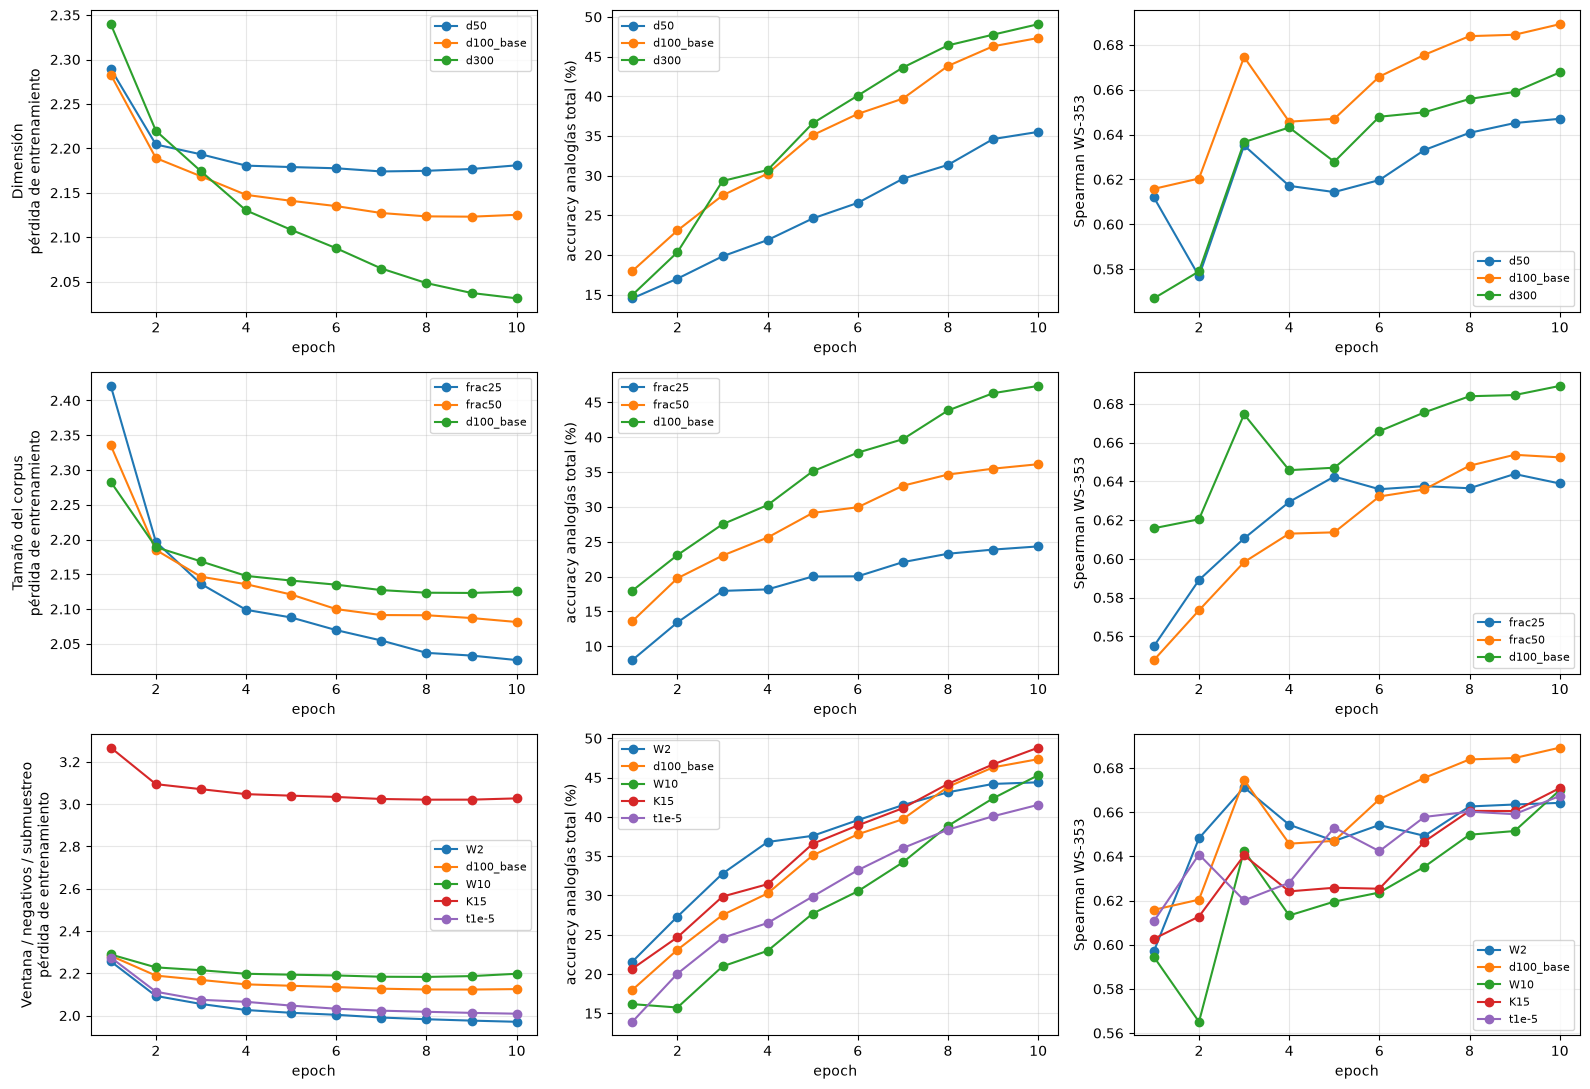

In [16]:
groups = {"Dimensión": ["d50", "d100_base", "d300"], "Tamaño del corpus": ["frac25", "frac50", "d100_base"], "Ventana / negativos / submuestreo": ["W2", "d100_base", "W10", "K15", "t1e-5"]}
fig, axes = plt.subplots(3, 3, figsize=(16, 11))
for row, (g, names) in enumerate(groups.items()):
    for name in names:
        h = results[name]["history"]; ep = [x["epoch"] for x in h]
        axes[row, 0].plot(ep, [x["loss"] for x in h], marker="o", label=name)
        axes[row, 1].plot(ep, [x["ana_total"] * 100 for x in h], marker="o", label=name)
        axes[row, 2].plot(ep, [x["ws353"] for x in h], marker="o", label=name)
    axes[row, 0].set_ylabel(g + "\npérdida de entrenamiento"); axes[row, 1].set_ylabel("accuracy analogías total (%)"); axes[row, 2].set_ylabel("Spearman WS-353")
    for a in axes[row]: a.set_xlabel("epoch"); a.grid(alpha=.3); a.legend(fontsize=8)
plt.tight_layout(); FIG.mkdir(exist_ok=True); plt.savefig(FIG / "iteraciones_curvas.png", dpi=150); plt.show()

In [17]:
# Vecinos más cercanos de las palabras de control, al final de cada epoch (corrida base, d=100)
nb_rows = []
for h in results["d100_base"]["history"]:
    nb_rows.append({"epoch": h["epoch"], **{w: ", ".join(x for x, _ in h["neighbors"][w]) for w in CONTROL}})
pd.set_option("display.max_colwidth", 70); display(pd.DataFrame(nb_rows).set_index("epoch"))

,king,france,computer,good,january,run
epoch,,,,,,
1,"murchad, ballala, satyashraya, silkbeard, diarmata","portugal, spain, germany, netherlands, italy","computers, software, e-reader, d20, graphics","pretty, 'm, really, quite, everything","october, february, december, november, june","runs, eighth-inning, unearned, conforto, pinch-hit"
2,"vladislaus, edward, prince, eorcenberht, monarch","italy, spain, austria, portugal, belgium","developers, interactive, graphics, software, nintendo","so, bad, excellent, better, very","december, february, april, march, november","ran, runs, running, walk-off, eighth-inning"
3,"monarch, ætheling, accession, sweyn, vi","spain, belgium, italy, portugal, austria","computers, poweranimator, software, computing, graphics","bad, "", you, votta, always","march, november, june, february, december","running, runs, ran, m-89, drive"
4,"prince, throne, duke, henry, vladislaus","portugal, spain, italy, austria, belgium","computers, software, hardware, real-time, console","bad, luck, pretty, hard, decent","february, march, april, june, december","drive, running, walk-off, for-3, runs"
5,"edward, throne, ætheling, ponthieu, sweyn","spain, italy, belgium, austria, germany","computers, graphics, spacewar, software, console","excellent, bad, pretty, happy, luck","february, march, april, december, june","runs, running, eighth-inning, ran, m-89"
6,"henry, edward, throne, earl, william","spain, italy, belgium, portugal, french","computers, software, computing, workstations, graphics","excellent, decent, bad, luck, pretty","december, june, february, november, march","runs, running, eighth-inning, ran, m-89"
7,"throne, prince, vi, edward, monarch","italy, spain, austria, belgium, french","computers, software, hardware, interface, user","excellent, bad, nice, nothing, luck","february, november, april, december, july","runs, ran, running, drive, eighth-inning"
8,"throne, edward, prince, ætheling, monarch","belgium, italy, spain, germany, portugal","computers, software, hardware, interface, technology","bad, luck, pretty, excellent, nice","december, november, march, june, february","running, runs, ran, m-89, eighth-inning"
9,"prince, queen, monarch, edward, vi","spain, belgium, italy, portugal, netherlands","computers, software, mainframe, simulation, interface","bad, pretty, fun, excellent, happy","february, december, march, june, november","running, runs, ran, eighth-inning, drive"


**¿Una pérdida más baja implica siempre mejores embeddings? No.**
- En la corrida base la pérdida se **estanca desde el epoch 8** (2.123 → 2.125) mientras las analogías siguen subiendo (43.8 % → 46.3 % → 47.3 %).
- Entre corridas con `K=5`, la correlación de Spearman entre pérdida final y accuracy de analogías es **0.12** (p = 0.78): `frac25` tiene **menor** pérdida (2.027) que la base (2.125) pero solo 24.3 % de analogías (vs 47.3 %); `t1e-5` (2.009) y `W2` (1.971) tienen menos pérdida que la base y peores analogías (41.5 % y 44.4 %); `d300` baja la pérdida (2.031) y mejora las analogías (49.1 %) pero empeora WS-353 (0.668 vs 0.689).
- La pérdida **no es comparable** entre configuraciones con distinta ventana, submuestreo o número de negativos (`K=15` tiene pérdida 3.03 porque suma más términos): cambia la distribución de pares y la tarea.

La pérdida mide qué tan bien se separa el contexto real del ruido (la tarea sustituta), no la calidad de la geometría del espacio; un corpus pequeño o un modelo con más capacidad ajustan mejor la tarea sin generalizar mejor las relaciones semánticas.

### 4.4 Word2Vec de gensim (referencia) y GloVe preentrenado
**gensim:** `Word2Vec(sg=1, negative=K, sample=t, window=W, vector_size=d)` entrenado sobre **exactamente el mismo flujo de tokens** (mismas líneas, mismo subconjunto de ~29.6 M de tokens, vocabulario ya filtrado con `min_count=5`, por lo que el vocabulario resulta idéntico) y con los hiperparámetros de la **mejor configuración de nuestro SGNS**. Se evalúa al final de cada epoch con las mismas funciones. **GloVe:** `glove-wiki-gigaword-100` tal cual (400 000 palabras, 100 dim).

In [18]:
from gensim.models import Word2Vec, KeyedVectors
from gensim.models.callbacks import CallbackAny2Vec

words_arr = np.array(words, dtype=object)
class LineCorpus:
    # Iterable reiniciable: devuelve cada línea del subconjunto como lista de palabras (mismo flujo que usa el SGNS).
    def __init__(self, n_use, n_tok): self.n_use, self.n_tok = n_use, n_tok
    def __iter__(self):
        off = 0
        for L in line_len[:self.n_use]:
            yield words_arr[train_ids[off:off + L]].tolist(); off += int(L)

class EpochEval(CallbackAny2Vec):
    def __init__(self): self.hist, self.t0, self.prev_loss = [], None, 0.0
    def on_epoch_begin(self, model): self.t0 = time.time()
    def on_epoch_end(self, model):
        secs = time.time() - self.t0; cum = model.get_latest_training_loss(); loss_ep = cum - self.prev_loss; self.prev_loss = cum
        ws, E = model.wv.index_to_key, model.wv.vectors
        ana = analogy_eval(ws, E, methods=("add",)); sim = similarity_eval(ws, E, WS353)
        self.hist.append(dict(epoch=len(self.hist) + 1, loss_cum_epoch=loss_ep, ana_sem=ana["add"]["sem"], ana_syn=ana["add"]["syn"], ana_total=ana["add"]["total"],
                              ws353=sim["spearman"], neighbors=neighbors(ws, E), epoch_secs=secs))
        h = self.hist[-1]; print(f"[gensim] ep {h['epoch']} | ana tot {h['ana_total']*100:5.2f} (sem {h['ana_sem']*100:5.2f} syn {h['ana_syn']*100:5.2f}) | WS353 {h['ws353']:.3f} | {secs:.0f}s")

def train_gensim(name, d, W, K, t, epochs, workers=8, seed=SEED):
    path = ART / "runs" / f"{name}.json"
    if path.exists(): return json.load(open(path))
    cb = EpochEval(); t0 = time.time()
    m = Word2Vec(vector_size=d, window=W, negative=K, sample=t, min_count=MIN_COUNT, sg=1, hs=0, workers=workers, seed=seed, epochs=epochs, compute_loss=True)
    corpus = LineCorpus(len(line_len), N_TOK); m.build_vocab(corpus); assert len(m.wv) == V, (len(m.wv), V)
    m.train(corpus, total_examples=m.corpus_count, epochs=epochs, callbacks=[cb], compute_loss=True)
    total = time.time() - t0
    m.wv.save(str(ART / "runs" / f"{name}.kv"))
    out = dict(name=name, config=dict(d=d, W=W, K=K, t=t, epochs=epochs, workers=workers, tokens_corpus=N_TOK, V=len(m.wv)), history=cb.hist, total_secs=total,
               train_secs=sum(h["epoch_secs"] for h in cb.hist))
    json.dump(out, open(path, "w"), default=float); return out

In [19]:
# Word2Vec de gensim con la configuración de la mejor corrida SGNS
g_res = train_gensim("gensim_best", d=best_cfg["d"], W=best_cfg["W"], K=best_cfg["K"], t=best_cfg["t"], epochs=best_cfg["epochs"])
gensim_kv = KeyedVectors.load(str(ART / "runs" / "gensim_best.kv"))
glove = api.load("glove-wiki-gigaword-100")                # GloVe preentrenado, sin entrenamiento adicional
print(f"gensim: {g_res['total_secs']/60:.1f} min | GloVe: {len(glove.key_to_index):,} palabras x {glove.vector_size}")
sgns_E = np.load(ART / "runs" / f"{best_name}.npy").astype(np.float32)

gensim: 3.1 min | GloVe: 400,000 palabras x 100


## 5. Verificación de la aritmética vectorial
Se comparan **tres conjuntos de embeddings**: nuestro SGNS (mejor configuración), el Word2Vec de gensim (misma configuración y mismo corpus) y GloVe-100 preentrenado.

### 5.1 Analogías individuales
`analogy(a, b, c, k)` resuelve «a es a b como c es a ?» con **3CosAdd** sobre vectores normalizados: $\arg\max_x \cos(x,\ \hat b-\hat a+\hat c)$, excluyendo $a$, $b$ y $c$. Primero se verifica que coincide con `most_similar(positive=[b,c], negative=[a])` de gensim.

In [20]:
from gensim.models import KeyedVectors

class Emb:
    # Envuelve (palabras, matriz) con vectores normalizados en GPU para consultas rápidas.
    def __init__(self, name, words, E):
        self.name, self.words = name, list(words); self.w2i = {w: i for i, w in enumerate(self.words)}
        self.En = F.normalize(torch.as_tensor(np.asarray(E, dtype=np.float32)).to(DEVICE), dim=1)
    def vec(self, w): return self.En[self.w2i[w]]
    @torch.no_grad()
    def analogy(self, a, b, c, k=5, exclude=True):
        q = self.vec(b) - self.vec(a) + self.vec(c)                      # a:b :: c:?   ->  b - a + c
        sims = self.En @ F.normalize(q, dim=0)                             # coseno con el vector resultante
        if exclude: sims[[self.w2i[a], self.w2i[b], self.w2i[c]]] = -2
        top = sims.topk(k); return [(self.words[i], float(s)) for s, i in zip(top.values.tolist(), top.indices.tolist())], sims
    def rank_of(self, sims, w): return int((sims > sims[self.w2i[w]]).sum().item()) + 1
    def to_kv(self):
        kv = KeyedVectors(self.En.shape[1]); kv.add_vectors(self.words, self.En.cpu().numpy()); return kv

# Verificación contra gensim: mismas 200 analogías aleatorias, vocabulario completo
def check_against_gensim(emb, n=200, seed=0):
    kv = emb.to_kv(); rng = random.Random(seed)
    qs = [q for qs_ in ANALOGIES.values() for q in qs_ if all(x in emb.w2i for x in q)]
    top1 = top5set = 0; sample = rng.sample(qs, n); maxdiff = 0.0
    for a, b, c, d in sample:
        mine, _ = emb.analogy(a, b, c, k=5); ref = kv.most_similar(positive=[b, c], negative=[a], topn=5)
        top1 += mine[0][0] == ref[0][0]; top5set += {w for w, _ in mine} == {w for w, _ in ref}
        maxdiff = max(maxdiff, max(abs(m[1] - r[1]) for m, r in zip(mine, ref)))
    return top1 / n, top5set / n, maxdiff

### Analogías propias (27, 7 tipos)
Para cada modelo se reporta el **top-5 con similitudes**, el **rango** de la respuesta correcta (1 = acierta) y su **similitud coseno con el vector resultante**.

In [21]:
MY_ANALOGIES = {
  "género":           [("man","woman","king","queen"), ("boy","girl","brother","sister"), ("he","she","his","her"), ("father","mother","son","daughter"), ("uncle","aunt","nephew","niece")],
  "país-capital":     [("france","paris","germany","berlin"), ("japan","tokyo","italy","rome"), ("spain","madrid","egypt","cairo"), ("china","beijing","russia","moscow")],
  "país-gentilicio":  [("france","french","germany","german"), ("spain","spanish","japan","japanese"), ("italy","italian","china","chinese")],
  "comparativos":     [("good","better","bad","worse"), ("big","bigger","small","smaller"), ("fast","faster","slow","slower"), ("large","larger","tall","taller")],
  "superlativos":     [("good","best","bad","worst"), ("big","biggest","small","smallest"), ("fast","fastest","slow","slowest")],
  "tiempos verbales": [("walk","walked","run","ran"), ("go","went","see","saw"), ("write","wrote","take","took"), ("play","played","work","worked")],
  "plurales":         [("cat","cats","dog","dogs"), ("child","children","man","men"), ("city","cities","country","countries"), ("house","houses","book","books")],
}

def individual_table(emb, exclude=True):
    rows = []
    for typ, qs in MY_ANALOGIES.items():
        for a, b, c, d in qs:
            if not all(x in emb.w2i for x in (a, b, c, d)): rows.append(dict(tipo=typ, analogía=f"{a}:{b}::{c}:?", esperada=d, top5="(fuera de vocab)", rango=None, cos_correcta=None)); continue
            top, sims = emb.analogy(a, b, c, 5, exclude)
            rows.append(dict(tipo=typ, analogía=f"{a}:{b}::{c}:?", esperada=d, top5=", ".join(f"{w} ({s:.2f})" for w, s in top),
                             rango=emb.rank_of(sims, d), cos_correcta=float(sims[emb.w2i[d]])))
    return pd.DataFrame(rows)

### 5.2 Evaluación sistemática sobre `questions-words.txt`
Vocabulario compartido: las **30 000 palabras más frecuentes presentes en los tres modelos**. Como cada modelo tiene su propio orden de frecuencia, se toma la **intersección** de los tres vocabularios y se ordena por la frecuencia en **nuestro corpus** (referencia común de los dos modelos entrenados), quedándose con las 30 000 primeras. Así las preguntas evaluadas son exactamente las mismas para todos.

### Análisis de paralelismo (vectores diferencia)
Si la aritmética funcionara de forma exacta, todos los pares de una misma relación (p. ej. `paris−france`, `berlin−germany`, …) tendrían el **mismo vector diferencia**. Se mide la **similitud coseno promedio entre los vectores diferencia** $(\hat b-\hat a)$ de pares distintos de una misma categoría de `questions-words.txt` (y, como línea base, entre pares de palabras aleatorias).

In [22]:
@torch.no_grad()
def parallelism(emb, restrict_words=None, max_pairs=300, seed=0):
    rng = random.Random(seed); res = {}; ok = lambda w: w in emb.w2i and (restrict_words is None or w in restrict_words)
    for cat, qs in ANALOGIES.items():
        pairs = list({(q[0], q[1]) for q in qs if ok(q[0]) and ok(q[1])} | {(q[2], q[3]) for q in qs if ok(q[2]) and ok(q[3])})
        if len(pairs) < 3: res[cat] = float("nan"); continue
        pairs = rng.sample(pairs, min(max_pairs, len(pairs)))
        D = F.normalize(torch.stack([emb.vec(b) - emb.vec(a) for a, b in pairs]), dim=1); S = D @ D.T
        n = len(pairs); res[cat] = float((S.sum() - n) / (n * (n - 1)))
    pool = [w for w in emb.words[:30000]]; r = torch.stack([emb.vec(rng.choice(pool)) - emb.vec(rng.choice(pool)) for _ in range(500)])
    D = F.normalize(r, dim=1); S = D @ D.T; res["_aleatorio"] = float((S.sum() - 500) / (500 * 499))
    res["_promedio"] = float(np.nanmean([v for k, v in res.items() if not k.startswith("_")]))
    return res

In [23]:
EMB = {"SGNS": Emb("SGNS", words, sgns_E), "gensim": Emb("gensim", gensim_kv.index_to_key, gensim_kv.vectors), "GloVe": Emb("GloVe", glove.index_to_key, glove.vectors)}

# 1) Verificación: nuestra analogy() vs most_similar() de gensim (200 preguntas aleatorias de questions-words, vocabulario completo)
rows = []
for n, e in EMB.items():
    t1, t5, md_ = check_against_gensim(e); rows.append({"modelo": n, "top-1 coincide %": t1 * 100, "top-5 (conjunto) coincide %": t5 * 100, "máx |Δ similitud|": md_})
display(pd.DataFrame(rows).set_index("modelo").style.format({"top-1 coincide %": "{:.1f}", "top-5 (conjunto) coincide %": "{:.1f}", "máx |Δ similitud|": "{:.1e}"}))

,top-1 coincide %,top-5 (conjunto) coincide %,máx |Δ similitud|
modelo,,,
SGNS,100.0,100.0,1.8e-07
gensim,100.0,100.0,2.4e-07
GloVe,100.0,100.0,2.4e-07


**Verificación:** nuestra función `analogy` reproduce a `most_similar` de gensim (misma respuesta y similitudes idénticas salvo error de punto flotante), así que la implementación de 3CosAdd es correcta.

In [24]:
# 2) Tablas de las 30 analogías propias, con exclusión de a, b, c (top-5 con similitud, rango y coseno de la respuesta correcta)
ind = {n: individual_table(e, exclude=True) for n, e in EMB.items()}
summ = []
for n, df in ind.items():
    d = df.dropna(subset=["rango"])
    for typ, g in d.groupby("tipo", sort=False): summ.append({"modelo": n, "tipo": typ, "top-1 %": (g["rango"] == 1).mean() * 100, "top-5 %": (g["rango"] <= 5).mean() * 100, "rango mediano": g["rango"].median(), "cos(correcta)": g["cos_correcta"].mean()})
    summ.append({"modelo": n, "tipo": "TOTAL (%d)" % len(d), "top-1 %": (d["rango"] == 1).mean() * 100, "top-5 %": (d["rango"] <= 5).mean() * 100, "rango mediano": d["rango"].median(), "cos(correcta)": d["cos_correcta"].mean()})
summ = pd.DataFrame(summ)
display(summ.style.format({"top-1 %": "{:.0f}", "top-5 %": "{:.0f}", "rango mediano": "{:.0f}", "cos(correcta)": "{:.3f}"}).hide(axis="index"))

modelo,tipo,top-1 %,top-5 %,rango mediano,cos(correcta)
SGNS,género,80,80,1,0.756
SGNS,país-capital,25,75,2,0.669
SGNS,país-gentilicio,100,100,1,0.818
SGNS,comparativos,75,100,1,0.685
SGNS,superlativos,33,67,3,0.558
SGNS,tiempos verbales,100,100,1,0.654
SGNS,plurales,100,100,1,0.657
SGNS,TOTAL (27),74,89,1,0.688
gensim,género,80,80,1,0.761
gensim,país-capital,25,50,9,0.668


In [25]:
pd.set_option("display.max_rows", 200, "display.width", 250, "display.max_colwidth", 95)
for n in EMB:
    print(f"\n===== {n} =====")
    display(ind[n][["tipo", "analogía", "esperada", "top5", "rango", "cos_correcta"]].style.format({"cos_correcta": "{:.3f}", "rango": "{:.0f}"}, na_rep="-").hide(axis="index"))


===== SGNS =====


tipo,analogía,esperada,top5,rango,cos_correcta
género,man:woman::king:?,queen,"queen (0.72), consort (0.66), monarch (0.64), empress (0.61), throne (0.60)",1,0.716
género,boy:girl::brother:?,sister,"cousin (0.72), daughter (0.70), son (0.70), husband (0.68), father (0.67)",9,0.626
género,he:she::his:?,her,"her (0.92), husband (0.69), herself (0.68), mother (0.58), sister (0.58)",1,0.922
género,father:mother::son:?,daughter,"daughter (0.84), wife (0.76), birth (0.72), eldest (0.72), grandson (0.70)",1,0.843
género,uncle:aunt::nephew:?,niece,"niece (0.67), wife (0.67), daughter (0.65), son (0.62), mother (0.62)",1,0.671
país-capital,france:paris::germany:?,berlin,"berlin (0.83), munich (0.74), budapest (0.70), vienna (0.69), frankfurt (0.68)",1,0.831
país-capital,japan:tokyo::italy:?,rome,"paris (0.69), naples (0.67), milan (0.67), berlin (0.64), brussels (0.63)",7,0.611
país-capital,spain:madrid::egypt:?,cairo,"egyptian (0.65), abu (0.59), cairo (0.58), syria (0.58), abou (0.56)",3,0.580
país-capital,china:beijing::russia:?,moscow,"olympics (0.68), moscow (0.65), sweden (0.60), olympic (0.59), paralympics (0.58)",2,0.652
país-gentilicio,france:french::germany:?,german,"german (0.87), austrian (0.76), russian (0.75), dutch (0.73), italian (0.71)",1,0.866



===== gensim =====


tipo,analogía,esperada,top5,rango,cos_correcta
género,man:woman::king:?,queen,"queen (0.70), regnant (0.68), consort (0.68), jagiellon (0.68), coronation (0.66)",1,0.703
género,boy:girl::brother:?,sister,"cousin (0.71), half-siblings (0.71), daughter (0.68), half-brothers (0.68), widowed (0.67)",55,0.609
género,he:she::his:?,her,"her (0.94), herself (0.68), husband (0.68), žofie (0.66), maybanke (0.64)",1,0.941
género,father:mother::son:?,daughter,"daughter (0.86), wife (0.81), eldest (0.79), grandchild (0.75), daughters (0.74)",1,0.863
género,uncle:aunt::nephew:?,niece,"niece (0.69), sister-in-law (0.66), wife (0.66), domna (0.64), cousin (0.64)",1,0.688
país-capital,france:paris::germany:?,berlin,"berlin (0.84), munich (0.79), frankfurt (0.73), vienna (0.73), budapest (0.71)",1,0.837
país-capital,japan:tokyo::italy:?,rome,"milan (0.69), paris (0.68), prague (0.66), düsseldorf (0.65), brussels (0.64)",27,0.597
país-capital,spain:madrid::egypt:?,cairo,"egyptian (0.63), abu (0.62), heliopolis (0.60), arab (0.60), bir (0.60)",16,0.559
país-capital,china:beijing::russia:?,moscow,"olympics (0.69), moscow (0.68), prague (0.65), sweden (0.65), innsbruck (0.64)",2,0.678
país-gentilicio,france:french::germany:?,german,"german (0.86), russian (0.78), austrian (0.78), dutch (0.77), swedish (0.71)",1,0.865



===== GloVe =====


tipo,analogía,esperada,top5,rango,cos_correcta
género,man:woman::king:?,queen,"queen (0.77), monarch (0.68), throne (0.68), daughter (0.66), princess (0.65)",1,0.770
género,boy:girl::brother:?,sister,"daughter (0.89), wife (0.88), father (0.88), cousin (0.87), son (0.86)",6,0.840
género,he:she::his:?,her,"her (0.99), mother (0.81), wife (0.79), my (0.78), herself (0.77)",1,0.985
género,father:mother::son:?,daughter,"daughter (0.95), wife (0.89), sister (0.84), niece (0.82), husband (0.82)",1,0.953
género,uncle:aunt::nephew:?,niece,"niece (0.90), granddaughter (0.81), daughter (0.77), cousin (0.77), grandmother (0.76)",1,0.896
país-capital,france:paris::germany:?,berlin,"berlin (0.88), frankfurt (0.80), vienna (0.77), munich (0.75), hamburg (0.72)",1,0.885
país-capital,japan:tokyo::italy:?,rome,"rome (0.77), milan (0.76), paris (0.71), naples (0.67), amsterdam (0.66)",1,0.769
país-capital,spain:madrid::egypt:?,cairo,"cairo (0.80), egyptian (0.71), amman (0.67), damascus (0.62), hosni (0.61)",1,0.803
país-capital,china:beijing::russia:?,moscow,"moscow (0.91), russian (0.75), kremlin (0.75), putin (0.71), ukraine (0.71)",1,0.912
país-gentilicio,france:french::germany:?,german,"german (0.96), austrian (0.78), swiss (0.77), swedish (0.73), polish (0.73)",1,0.960


#### Repetición **sin excluir** las palabras de la consulta
Sin la exclusión, el vecino más cercano del vector $\hat b-\hat a+\hat c$ suele ser una de las propias palabras de la consulta. Se cuenta cuántas veces el primer lugar es $b$, $c$, $a$ o la respuesta correcta $d$.

In [26]:
rows, examples = [], {}
for n, e in EMB.items():
    cnt = collections.Counter(); tot = 0
    for typ, qs in MY_ANALOGIES.items():
        for a, b, c, d in qs:
            if not all(x in e.w2i for x in (a, b, c, d)): continue
            top, _ = e.analogy(a, b, c, 5, exclude=False); w = top[0][0]; tot += 1
            cnt["b (2.º argumento)"] += w == b; cnt["c (3.er argumento)"] += w == c; cnt["a"] += w == a; cnt["d (correcta)"] += w == d
            cnt["otra palabra"] += w not in (a, b, c, d)
            if (a, b, c) == ("man", "woman", "king"): examples[n] = top
    rows.append({"modelo": n, "n": tot, **{k: v / tot * 100 for k, v in cnt.items()}})
display(pd.DataFrame(rows).set_index("modelo").style.format("{:.0f}", subset=pd.IndexSlice[:, ["b (2.º argumento)", "c (3.er argumento)", "a", "d (correcta)", "otra palabra"]]))
for n, top in examples.items(): print(f"{n:7s} man:woman::king:?  sin exclusión ->", ", ".join(f"{w} ({s:.2f})" for w, s in top))

,n,b (2.º argumento),c (3.er argumento),a,d (correcta),otra palabra
modelo,,,,,,
SGNS,27,26,48,0,22,4
gensim,27,22,44,0,30,4
GloVe,27,11,33,0,48,7


SGNS    man:woman::king:?  sin exclusión -> king (0.77), queen (0.72), consort (0.66), monarch (0.64), empress (0.61)
gensim  man:woman::king:?  sin exclusión -> king (0.77), queen (0.70), regnant (0.68), consort (0.68), jagiellon (0.68)
GloVe   man:woman::king:?  sin exclusión -> king (0.84), queen (0.77), monarch (0.68), throne (0.68), daughter (0.66)


In [27]:
# 5.2 Evaluación sistemática: vocabulario compartido (30 000 más frecuentes en los tres modelos; orden = frecuencia en nuestro corpus)
shared = [w for w in words if w in glove.key_to_index][:30_000]; shared_set = set(shared)
print("tamaño del vocabulario compartido:", len(shared), "| ejemplo:", shared[:8])
sysres = {n: analogy_eval(e.words, e.En, allowed=shared, methods=("add", "mul")) for n, e in EMB.items()}
cov = sysres["SGNS"]["coverage"]; assert all(sysres[n]["coverage"]["per_cat"] == cov["per_cat"] for n in EMB)   # mismas preguntas en los tres
print(f"cobertura: {cov['n_eval']:,} / {cov['n_total']:,} preguntas evaluadas ({cov['n_eval'] / cov['n_total'] * 100:.1f} %) — idénticas en los tres modelos")

rows = []
for cat in CATS + ["semántica", "sintáctica", "TOTAL"]:
    r = {"categoría": cat}
    if cat in CATS: r["cobertura"] = f"{cov['per_cat'][cat][0]}/{cov['per_cat'][cat][1]}"
    else: r["cobertura"] = ""
    for n in EMB:
        for m, lab in (("add", "3CosAdd"), ("mul", "3CosMul")):
            r[f"{n} {lab}"] = sysres[n][m]["per_cat"][cat] * 100 if cat in CATS else sysres[n][m][{"semántica": "sem", "sintáctica": "syn", "TOTAL": "total"}[cat]] * 100
    rows.append(r)
sys_df = pd.DataFrame(rows).set_index("categoría"); display(sys_df.style.format({c: "{:.1f}" for c in sys_df.columns if c != "cobertura"}, na_rep="-"))

tamaño del vocabulario compartido: 30000 | ejemplo: ['the', ',', '.', 'of', 'and', 'in', 'to', 'a']


cobertura: 11,611 / 19,544 preguntas evaluadas (59.4 %) — idénticas en los tres modelos


,cobertura,SGNS 3CosAdd,SGNS 3CosMul,gensim 3CosAdd,gensim 3CosMul,GloVe 3CosAdd,GloVe 3CosMul
categoría,,,,,,,
capital-common-countries,380/506,71.3,66.6,57.1,53.4,92.9,91.1
capital-world,1046/4524,55.2,47.6,43.0,38.1,88.3,85.9
currency,70/866,0.0,1.4,0.0,1.4,5.7,5.7
city-in-state,1574/2467,29.5,24.8,27.0,25.1,30.9,27.8
family,342/506,48.0,45.0,52.3,48.8,88.0,86.8
gram1-adjective-to-adverb,812/992,15.4,11.1,16.6,13.2,27.8,27.8
gram2-opposite,272/812,9.2,7.0,11.8,8.5,27.2,23.9
gram3-comparative,1332/1332,48.9,45.3,56.8,54.9,80.3,78.2
gram4-superlative,702/1122,30.8,31.1,30.8,31.2,61.4,62.1


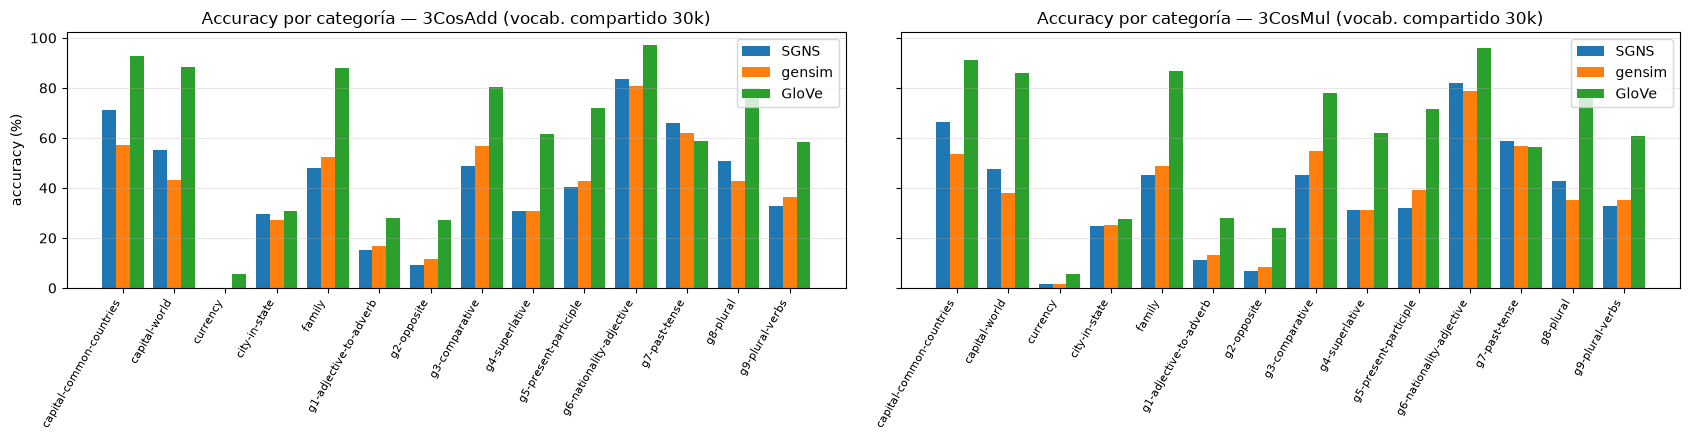

In [28]:
fig, ax = plt.subplots(1, 2, figsize=(17, 4.5), sharey=True)
for a, (m, lab) in zip(ax, (("add", "3CosAdd"), ("mul", "3CosMul"))):
    x = np.arange(len(CATS)); w = 0.27
    for k, n in enumerate(EMB): a.bar(x + (k - 1) * w, [sysres[n][m]["per_cat"][c] * 100 for c in CATS], w, label=n)
    a.set_xticks(x); a.set_xticklabels([c.replace("gram", "g") for c in CATS], rotation=60, ha="right", fontsize=8); a.set_title(f"Accuracy por categoría — {lab} (vocab. compartido 30k)"); a.grid(alpha=.3, axis="y"); a.legend()
ax[0].set_ylabel("accuracy (%)"); plt.tight_layout(); FIG.mkdir(exist_ok=True); plt.savefig(FIG / "analogias_categoria.png", dpi=150); plt.show()

In [29]:
# Paralelismo de los vectores diferencia (b - a) dentro de cada categoría, vocabulario compartido
par = {n: parallelism(e, restrict_words=shared_set) for n, e in EMB.items()}
par_df = pd.DataFrame(par); par_df.index = [i if not i.startswith("_") else {"_aleatorio": "(pares aleatorios)", "_promedio": "PROMEDIO categorías"}[i] for i in par_df.index]
display(par_df.style.format("{:.3f}"))

,SGNS,gensim,GloVe
capital-common-countries,0.326,0.324,0.582
capital-world,0.230,0.246,0.567
currency,0.242,0.285,0.266
city-in-state,0.195,0.201,0.341
family,0.236,0.249,0.507
gram1-adjective-to-adverb,0.115,0.127,0.271
gram2-opposite,0.083,0.097,0.231
gram3-comparative,0.270,0.309,0.424
gram4-superlative,0.266,0.281,0.465
gram5-present-participle,0.156,0.188,0.319


### t-SNE alrededor de ~500 palabras de grupos temáticos
Se proyectan a 2D (t-SNE sobre vectores normalizados, perplejidad 30) palabras de 10 grupos temáticos para **nuestro mejor SGNS** y, como referencia, para GloVe. Además se mide cuantitativamente la separación de grupos con el **coeficiente de silueta (coseno)** en el espacio original de 100/300 dimensiones.

478 palabras en 15 grupos: {'países': 74, 'números': 44, 'animales': 46, 'verbos': 43, 'colores': 18, 'profesiones': 31, 'ciudades': 43, 'tiempo': 26, 'familia': 24, 'cuerpo': 24, 'comida': 29, 'deportes': 19, 'transporte': 20, 'naturaleza': 23, 'ropa': 14}


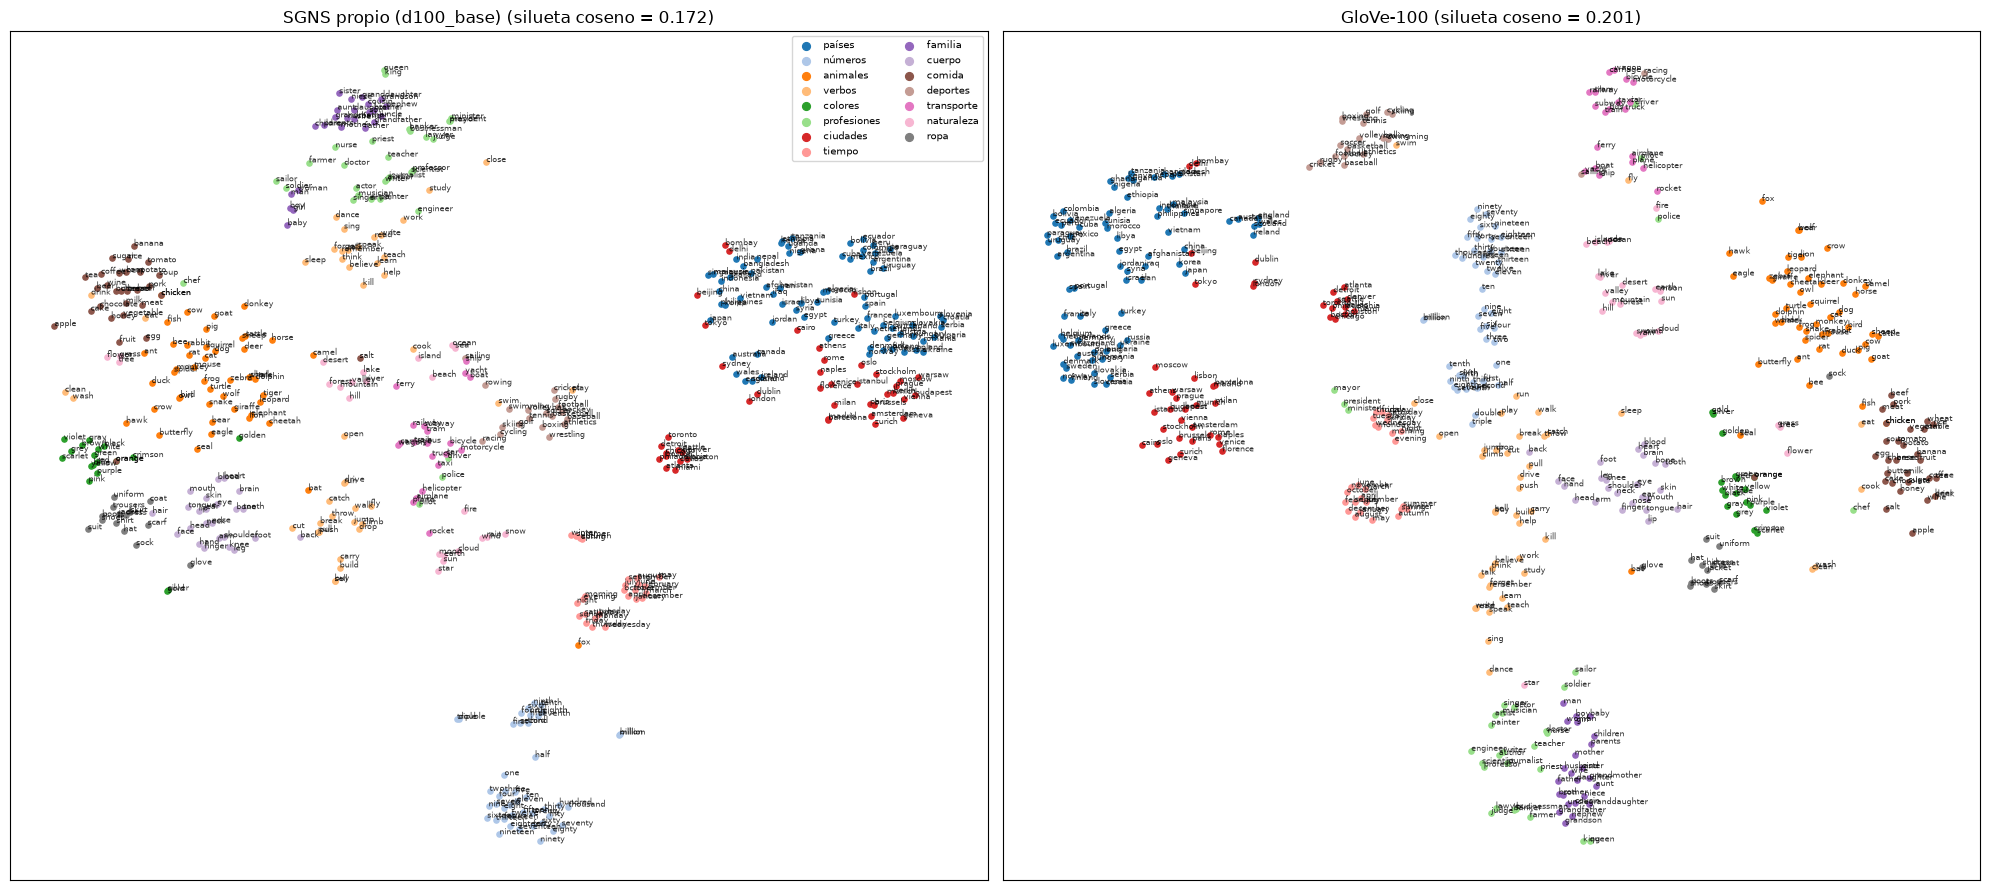

silueta: {'SGNS': 0.17221276462078094, 'GloVe': 0.20098455250263214}


In [30]:
from sklearn.manifold import TSNE
from sklearn.metrics import silhouette_score

GROUPS = {
 "países": "france germany italy spain japan china russia india brazil canada australia mexico egypt greece turkey sweden norway poland ireland portugal argentina chile peru iran iraq korea vietnam thailand kenya nigeria ukraine austria belgium denmark finland switzerland netherlands cuba israel pakistan indonesia colombia venezuela scotland wales england hungary romania bulgaria serbia croatia syria jordan morocco".split(),
 "números": "one two three four five six seven eight nine ten eleven twelve thirteen fourteen fifteen sixteen seventeen eighteen nineteen twenty thirty forty fifty sixty seventy eighty ninety hundred thousand million billion first second third fourth fifth sixth seventh eighth ninth tenth half double triple".split(),
 "animales": "dog cat horse cow pig sheep bird fish lion tiger bear wolf fox rabbit mouse elephant monkey snake eagle whale shark deer duck goat chicken frog turtle spider bee butterfly ant cattle donkey camel zebra giraffe leopard cheetah owl hawk crow dolphin seal squirrel bat rat".split(),
 "verbos": "run walk talk eat drink sleep write read play work build break open close buy sell speak sing dance swim jump climb drive fly cook wash clean carry throw catch push pull cut drop kill help teach learn study think believe remember forget".split(),
 "colores": "red blue green yellow black white orange purple pink brown grey gray gold silver golden crimson violet scarlet".split(),
 "profesiones": "doctor teacher lawyer engineer nurse farmer soldier pilot actor singer writer painter judge priest minister king queen president mayor chef scientist professor author journalist businessman banker police sailor driver artist musician".split(),
 "ciudades": "paris london berlin rome madrid tokyo moscow beijing cairo vienna athens lisbon dublin oslo stockholm warsaw prague budapest istanbul delhi bombay sydney toronto chicago boston seattle houston denver detroit atlanta dallas miami philadelphia amsterdam brussels geneva zurich munich barcelona milan venice florence naples".split(),
 "tiempo": "january february march april may june july august september october november december monday tuesday wednesday thursday friday saturday sunday spring summer autumn winter morning evening night".split(),
 "familia": "father mother son daughter brother sister uncle aunt nephew niece husband wife grandfather grandmother parents children cousin grandson granddaughter boy girl man woman baby".split(),
 "cuerpo": "head hand arm leg foot eye ear nose mouth heart brain finger hair skin face neck shoulder knee back blood bone tooth tongue lip".split(),
 "comida": "bread cheese milk meat rice sugar salt butter apple orange banana potato tomato beef pork chicken egg wine beer coffee tea soup cake chocolate fruit vegetable corn wheat honey".split(),
 "deportes": "football baseball basketball soccer tennis golf hockey rugby cricket boxing swimming cycling skiing wrestling volleyball athletics racing sailing rowing".split(),
 "transporte": "car bus train plane ship boat truck bicycle motorcycle taxi airplane helicopter subway tram ferry rocket yacht carriage wagon railway".split(),
 "naturaleza": "river mountain lake ocean sea forest desert island tree flower grass rain snow wind sun moon star cloud fire earth valley hill beach".split(),
 "ropa": "shirt dress hat shoes coat jacket skirt trousers glove scarf boots sock suit uniform".split(),
}
GROUPS["países"] += "luxembourg slovakia slovenia bolivia ecuador uruguay paraguay afghanistan nepal bangladesh malaysia philippines singapore ethiopia ghana tanzania uganda algeria libya tunisia".split()
common = lambda w: w in EMB["SGNS"].w2i and w in EMB["GloVe"].w2i
sel, lab = [], []
for g, ws_ in GROUPS.items():
    ws_ = [w for w in dict.fromkeys(ws_) if common(w)]; sel += ws_; lab += [g] * len(ws_)
print(f"{len(sel)} palabras en {len(GROUPS)} grupos:", {g: lab.count(g) for g in GROUPS})

def tsne_plot(ax, emb, title):
    X = emb.En[[emb.w2i[w] for w in sel]].cpu().numpy()
    Z = TSNE(n_components=2, perplexity=30, init="pca", random_state=SEED, metric="cosine").fit_transform(X)
    sil = silhouette_score(X, lab, metric="cosine")
    cmap = plt.get_cmap("tab20")
    for k, g in enumerate(GROUPS):
        m = np.array(lab) == g; ax.scatter(Z[m, 0], Z[m, 1], s=14, color=cmap(k), label=g)
        for z, w in zip(Z[m], np.array(sel)[m]): ax.annotate(w, z, fontsize=5.5, alpha=.8)
    ax.set_title(f"{title} (silueta coseno = {sil:.3f})"); ax.set_xticks([]); ax.set_yticks([]); return sil
fig, ax = plt.subplots(1, 2, figsize=(20, 9)); sils = {"SGNS": tsne_plot(ax[0], EMB["SGNS"], f"SGNS propio ({best_name})"), "GloVe": tsne_plot(ax[1], EMB["GloVe"], "GloVe-100")}
ax[0].legend(loc="best", fontsize=7, markerscale=1.5, ncol=2); plt.tight_layout(); FIG.mkdir(exist_ok=True); plt.savefig(FIG / "tsne.png", dpi=150); plt.show(); print("silueta:", sils)

## 6. Pipeline end-to-end: clasificación de AG News
**texto → tokens → vectores → modelo → salida.** Se usa el **mismo `tokenize()` de la sección 2** (minúsculas, contracciones PTB, números conservados). Se separa el **10 % del train como validación (estratificado)**; el test oficial (7 600 noticias) solo se usa **una vez por modelo seleccionado**.

**Modelos:**
1. **Baseline:** TF-IDF (unigramas + bigramas) + regresión logística.
2. **Embeddings aleatorios:** `nn.EmbeddingBag(mean)` + MLP, tabla inicializada al azar y entrenada con la tarea (vocabulario = palabras con frecuencia ≥ 2 en el train; el resto → `<unk>`).
3. **SGNS propio / Word2Vec gensim / GloVe:** el mismo clasificador inicializado con cada tabla, en dos variantes: **(a) congelada** y **(b) con fine-tuning**. Los tokens fuera del vocabulario del embedding se **omiten** de la bolsa (se reporta su porcentaje).

Clasificador: `EmbeddingBag(mean, padding_idx=0)` → `Linear(100,256)` → ReLU → Dropout(0.3) → `Linear(256,4)`; Adam (lr 1e-3), batch 256, hasta 10 epochs (40 en las variantes **congeladas**, que solo entrenan el MLP y convergen más lento), se conserva el epoch con mejor F1-macro de validación.

In [31]:
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, confusion_matrix

LABELS = news["train"].features["label"].names
tok_path = ART / "agnews_tokens.pkl"
if tok_path.exists(): ag_tr_tok, ag_te_tok = pickle.load(open(tok_path, "rb"))
else:
    ag_tr_tok = [tokenize(t) for t in tqdm(news["train"]["text"], desc="tokenizando AG train")]
    ag_te_tok = [tokenize(t) for t in tqdm(news["test"]["text"], desc="tokenizando AG test")]
    pickle.dump((ag_tr_tok, ag_te_tok), open(tok_path, "wb"))
y_all = np.array(news["train"]["label"]); y_te = np.array(news["test"]["label"])

idx_tr, idx_va = train_test_split(np.arange(len(y_all)), test_size=0.10, stratify=y_all, random_state=SEED)
tok_tr, tok_va = [ag_tr_tok[i] for i in idx_tr], [ag_tr_tok[i] for i in idx_va]; y_tr, y_va = y_all[idx_tr], y_all[idx_va]
lens = np.array([len(t) for t in ag_tr_tok])
print(f"train {len(tok_tr):,} | val {len(tok_va):,} | test {len(ag_te_tok):,} | clases {LABELS}")
print(f"longitud en tokens: media {lens.mean():.1f}, p95 {np.percentile(lens, 95):.0f}, máx {lens.max()}")
print("distribución val:", np.bincount(y_va) / len(y_va))

train 108,000 | val 12,000 | test 7,600 | clases ['World', 'Sports', 'Business', 'Sci/Tech']
longitud en tokens: media 45.2, p95 69, máx 261
distribución val: [0.25 0.25 0.25 0.25]


In [32]:
# Tres conjuntos de embeddings (el mejor SGNS, gensim con su misma configuración y GloVe)
EMBS = {"SGNS": (list(words), sgns_E), "gensim": (list(gensim_kv.index_to_key), gensim_kv.vectors), "GloVe": (list(glove.index_to_key), glove.vectors)}

# Porcentaje de tokens de AG News fuera del vocabulario de cada embedding (train+test)
all_tok = [t for ts in (ag_tr_tok, ag_te_tok) for doc in ts for t in doc]
cnt_ag = collections.Counter(all_tok); n_ag = sum(cnt_ag.values())
oov_rows = []
for name, (ws, _) in EMBS.items():
    vs = set(ws); oov_tok = sum(c for w, c in cnt_ag.items() if w not in vs); oov_typ = sum(1 for w in cnt_ag if w not in vs)
    oov_rows.append({"embedding": name, "|V|": len(ws), "tokens AG fuera de vocab %": oov_tok / n_ag * 100, "tipos AG fuera de vocab %": oov_typ / len(cnt_ag) * 100})
oov_df = pd.DataFrame(oov_rows).set_index("embedding"); display(oov_df.style.format({"|V|": "{:,}", "tokens AG fuera de vocab %": "{:.2f}", "tipos AG fuera de vocab %": "{:.2f}"}))
print("Tokens totales AG News:", f"{n_ag:,}", "| tipos:", f"{len(cnt_ag):,}")

,|V|,tokens AG fuera de vocab %,tipos AG fuera de vocab %
embedding,,,
SGNS,"100,844",3.12,46.73
gensim,"100,844",3.12,46.73
GloVe,"400,000",0.88,22.76


Tokens totales AG News: 5,759,102 | tipos: 82,201


In [33]:
MAXLEN = 128
def encode(tok_lists, w2id, unk_id=None):
    # IDs con fila 0 = padding y fila 1 = <unk>; los tokens fuera de vocab se omiten (o van a <unk> si unk_id).
    X = np.zeros((len(tok_lists), MAXLEN), dtype=np.int64)
    for i, toks in enumerate(tok_lists):
        ids = []
        for t in toks:
            j = w2id.get(t)
            if j is not None: ids.append(j)
            elif unk_id is not None: ids.append(unk_id)
        if not ids: ids = [1]
        ids = ids[:MAXLEN]; X[i, :len(ids)] = ids
    return torch.as_tensor(X, device=DEVICE)

def prf(y, p):
    P, R, F1, _ = precision_recall_fscore_support(y, p, average="macro", zero_division=0)
    return dict(acc=accuracy_score(y, p), precision=P, recall=R, f1=F1)

class BagMLP(nn.Module):
    def __init__(self, n_rows, dim, init=None, freeze=False, hidden=256, n_cls=4):
        super().__init__()
        if init is not None: self.emb = nn.EmbeddingBag.from_pretrained(torch.as_tensor(init, dtype=torch.float32), freeze=freeze, mode="mean", padding_idx=0)
        else: self.emb = nn.EmbeddingBag(n_rows, dim, mode="mean", padding_idx=0)
        self.mlp = nn.Sequential(nn.Linear(dim, hidden), nn.ReLU(), nn.Dropout(0.3), nn.Linear(hidden, n_cls))
    def forward(self, x): return self.mlp(self.emb(x))

@torch.no_grad()
def predict(model, X, bs=4096):
    model.eval(); out = [model(X[i:i + bs]) for i in range(0, len(X), bs)]; return torch.cat(out)

def fit_bag(Xtr, ytr, Xva, yva, n_rows, dim, init=None, freeze=False, epochs=10, lr=1e-3, bs=256, seed=SEED):
    torch.manual_seed(seed); model = BagMLP(n_rows, dim, init, freeze).to(DEVICE)
    params = [p for p in model.parameters() if p.requires_grad]; opt = torch.optim.Adam(params, lr=lr)
    ytr_t, yva_t = torch.as_tensor(ytr, device=DEVICE), torch.as_tensor(yva, device=DEVICE)
    hist, best, best_state = [], -1, None; t0 = time.time()
    for ep in range(epochs):
        model.train(); perm = torch.randperm(len(Xtr), device=DEVICE); tl = 0.0
        for i in range(0, len(perm), bs):
            b = perm[i:i + bs]; loss = F.cross_entropy(model(Xtr[b]), ytr_t[b]); opt.zero_grad(set_to_none=True); loss.backward(); opt.step(); tl += loss.item() * len(b)
        lv = predict(model, Xva); vloss = F.cross_entropy(lv, yva_t).item(); m = prf(yva, lv.argmax(1).cpu().numpy())
        hist.append(dict(epoch=ep + 1, train_loss=tl / len(Xtr), val_loss=vloss, **{"val_" + k: v for k, v in m.items()}))
        if m["f1"] > best: best, best_epoch, best_state = m["f1"], ep + 1, {k: v.detach().clone() for k, v in model.state_dict().items()}
    model.load_state_dict(best_state)
    n_par = sum(p.numel() for p in model.parameters()); n_tr = sum(p.numel() for p in model.parameters() if p.requires_grad)
    return dict(model=model, hist=hist, best_epoch=best_epoch, val=hist[best_epoch - 1], secs=time.time() - t0, params=n_par, trainable=n_tr)

In [34]:
def make_inputs(init, toks_tr, toks_va, toks_te):
    # Devuelve (Xtr, Xva, Xte, n_rows, init_matrix) para una inicialización dada.
    if init == "Aleatorio":
        c = collections.Counter(t for d in toks_tr for t in d); vocab = [w for w, n in c.items() if n >= 2]
        w2id = {w: i + 2 for i, w in enumerate(vocab)}; enc = lambda L: encode(L, w2id, unk_id=1)
        return enc(toks_tr), enc(toks_va), enc(toks_te), len(vocab) + 2, None
    ws, E = EMBS[init]; w2id = {w: i + 2 for i, w in enumerate(ws)}; enc = lambda L: encode(L, w2id)
    M = np.zeros((len(ws) + 2, E.shape[1]), dtype=np.float32); M[2:] = E
    return enc(toks_tr), enc(toks_va), enc(toks_te), M.shape[0], M

def run_variants(init, frac=1.0, seed=SEED, epochs=10):
    # Entrena las variantes de una inicialización y devuelve la mejor según validación (test se evalúa una sola vez).
    if frac < 1:
        sub, _ = train_test_split(np.arange(len(y_tr)), train_size=frac, stratify=y_tr, random_state=seed)
        ttr, ytr = [tok_tr[i] for i in sub], y_tr[sub]
    else: ttr, ytr = tok_tr, y_tr
    Xtr, Xva, Xte, n_rows, M = make_inputs(init, ttr, tok_va, ag_te_tok)
    dim = 100 if M is None else M.shape[1]
    variants = {"entrenado": dict()} if init == "Aleatorio" else {"congelado": dict(freeze=True), "fine-tuning": dict(freeze=False)}
    fits = {v: fit_bag(Xtr, ytr, Xva, y_va, n_rows, dim, init=M, epochs=epochs * (4 if kw.get('freeze') else 1), seed=seed, **kw) for v, kw in variants.items()}
    best_v = max(fits, key=lambda v: fits[v]["val"]["val_f1"]); lt = predict(fits[best_v]["model"], Xte); pred = lt.argmax(1).cpu().numpy()
    test = dict(**prf(y_te, pred), cm=confusion_matrix(y_te, pred), variant=best_v)
    summary = {v: {k: f[k] for k in ("hist", "best_epoch", "val", "secs", "params", "trainable")} for v, f in fits.items()}
    del fits; torch.cuda.empty_cache(); return dict(summary=summary, test=test)

In [35]:
# ---- Baseline TF-IDF + regresión logística ----
def run_baseline(frac=1.0, seed=SEED):
    if frac < 1:
        sub, _ = train_test_split(np.arange(len(y_tr)), train_size=frac, stratify=y_tr, random_state=seed); ttr, ytr = [tok_tr[i] for i in sub], y_tr[sub]
    else: ttr, ytr = tok_tr, y_tr
    t0 = time.time(); vec = TfidfVectorizer(tokenizer=lambda x: x, preprocessor=lambda x: x, token_pattern=None, lowercase=False, ngram_range=(1, 2), min_df=2, sublinear_tf=True)
    Xtr = vec.fit_transform(ttr); Xva, Xte = vec.transform(tok_va), vec.transform(ag_te_tok)
    best = None
    for C in (1, 10, 30):                                              # C se elige con validación
        clf = LogisticRegression(C=C, max_iter=300).fit(Xtr, ytr); m = prf(y_va, clf.predict(Xva))
        if best is None or m["f1"] > best[0]["f1"]: best = (m, clf, C)
    m, clf, C = best; pred = clf.predict(Xte)
    return dict(val=m, test=dict(**prf(y_te, pred), cm=confusion_matrix(y_te, pred), variant=f"C={C}"), secs=time.time() - t0, params=Xtr.shape[1] * 4 + 4, features=Xtr.shape[1])

cls_path = ART / "cls_results.pkl"
cls = pickle.load(open(cls_path, "rb")) if cls_path.exists() else {}
FRACS = (0.01, 0.05, 0.10, 0.25, 0.50, 1.0)
for frac in FRACS:
    if ("TF-IDF", frac) not in cls: cls[("TF-IDF", frac)] = run_baseline(frac)
    for init in ("Aleatorio", "SGNS", "gensim", "GloVe"):
        if (init, frac) not in cls:
            t0 = time.time(); cls[(init, frac)] = run_variants(init, frac); print(f"{init:10s} frac={frac:<5} -> {cls[(init, frac)]['test']['variant']:12s} | {time.time()-t0:.0f}s")
    pickle.dump(cls, open(cls_path, "wb"))
print("listo")

listo


### 6.1 Resultados en validación (100 % del train)
Accuracy, precisión, recall y F1 (macro) en validación, parámetros totales/entrenables y tiempo de entrenamiento de **todas** las variantes.

,modelo,variante,acc,precision,recall,F1,params totales,entrenables,tiempo (s),mejor epoch
0,TF-IDF + LogReg,C=10,0.9295,0.9293,0.9295,0.9294,"1,742,016","1,742,016",146,-
1,Aleatorio,entrenado,0.9130,0.9129,0.9130,0.9129,"4,810,284","4,810,284",15,8.000000
2,SGNS,congelado,0.8978,0.8979,0.8978,0.8976,"10,111,484","26,884",22,38.000000
3,SGNS,fine-tuning,0.9189,0.9197,0.9189,0.9188,"10,111,484","10,111,484",23,3.000000
4,gensim,congelado,0.9012,0.9010,0.9012,0.9010,"10,111,484","26,884",22,40.000000
5,gensim,fine-tuning,0.9189,0.9197,0.9189,0.9187,"10,111,484","10,111,484",24,3.000000
6,GloVe,congelado,0.9132,0.9134,0.9132,0.9131,"40,027,084","26,884",22,33.000000
7,GloVe,fine-tuning,0.9248,0.9253,0.9248,0.9247,"40,027,084","40,027,084",72,5.000000


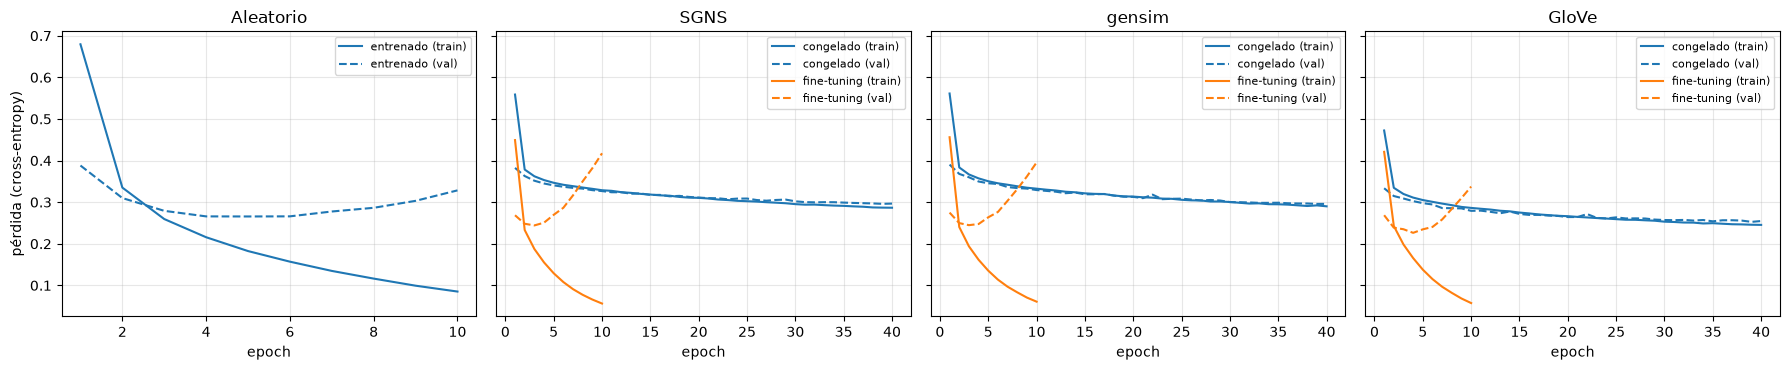

In [36]:
rows = [{"modelo": "TF-IDF + LogReg", "variante": cls[("TF-IDF", 1.0)]["test"]["variant"], "acc": cls[("TF-IDF", 1.0)]["val"]["acc"], "precision": cls[("TF-IDF", 1.0)]["val"]["precision"],
         "recall": cls[("TF-IDF", 1.0)]["val"]["recall"], "F1": cls[("TF-IDF", 1.0)]["val"]["f1"], "params totales": cls[("TF-IDF", 1.0)]["params"], "entrenables": cls[("TF-IDF", 1.0)]["params"],
         "tiempo (s)": cls[("TF-IDF", 1.0)]["secs"], "mejor epoch": None}]
for init in ("Aleatorio", "SGNS", "gensim", "GloVe"):
    for v, s in cls[(init, 1.0)]["summary"].items():
        rows.append({"modelo": init, "variante": v, "acc": s["val"]["val_acc"], "precision": s["val"]["val_precision"], "recall": s["val"]["val_recall"], "F1": s["val"]["val_f1"],
                     "params totales": s["params"], "entrenables": s["trainable"], "tiempo (s)": s["secs"], "mejor epoch": s["best_epoch"]})
val_df = pd.DataFrame(rows); display(val_df.style.format({"acc": "{:.4f}", "precision": "{:.4f}", "recall": "{:.4f}", "F1": "{:.4f}", "params totales": "{:,}", "entrenables": "{:,}", "tiempo (s)": "{:.0f}"}, na_rep="-"))

fig, ax = plt.subplots(1, 4, figsize=(18, 3.8), sharey=True)
for a, init in zip(ax, ("Aleatorio", "SGNS", "gensim", "GloVe")):
    for v, s in cls[(init, 1.0)]["summary"].items():
        e = [h["epoch"] for h in s["hist"]]; l, = a.plot(e, [h["train_loss"] for h in s["hist"]], label=f"{v} (train)")
        a.plot(e, [h["val_loss"] for h in s["hist"]], "--", color=l.get_color(), label=f"{v} (val)")
    a.set_title(init); a.set_xlabel("epoch"); a.grid(alpha=.3); a.legend(fontsize=8)
ax[0].set_ylabel("pérdida (cross-entropy)"); plt.tight_layout(); FIG.mkdir(exist_ok=True); plt.savefig(FIG / "cls_loss.png", dpi=150); plt.show()

### 6.2 Evaluación final en test (una sola vez por modelo seleccionado) y SimLex-999
Para cada inicialización se toma la **mejor variante según F1 de validación** y se evalúa una única vez sobre el test oficial. También se reporta la correlación de Spearman en **SimLex-999** (reservado para esta etapa) de los tres conjuntos de embeddings.

,modelo,variante,acc,precision,recall,f1
0,TF-IDF + LogReg,C=10,0.9263,0.9262,0.9263,0.9262
1,Aleatorio,entrenado,0.9083,0.9081,0.9083,0.9082
2,SGNS,fine-tuning,0.9151,0.9155,0.9151,0.9151
3,gensim,fine-tuning,0.9141,0.9145,0.9141,0.9139
4,GloVe,fine-tuning,0.9213,0.9219,0.9213,0.9213


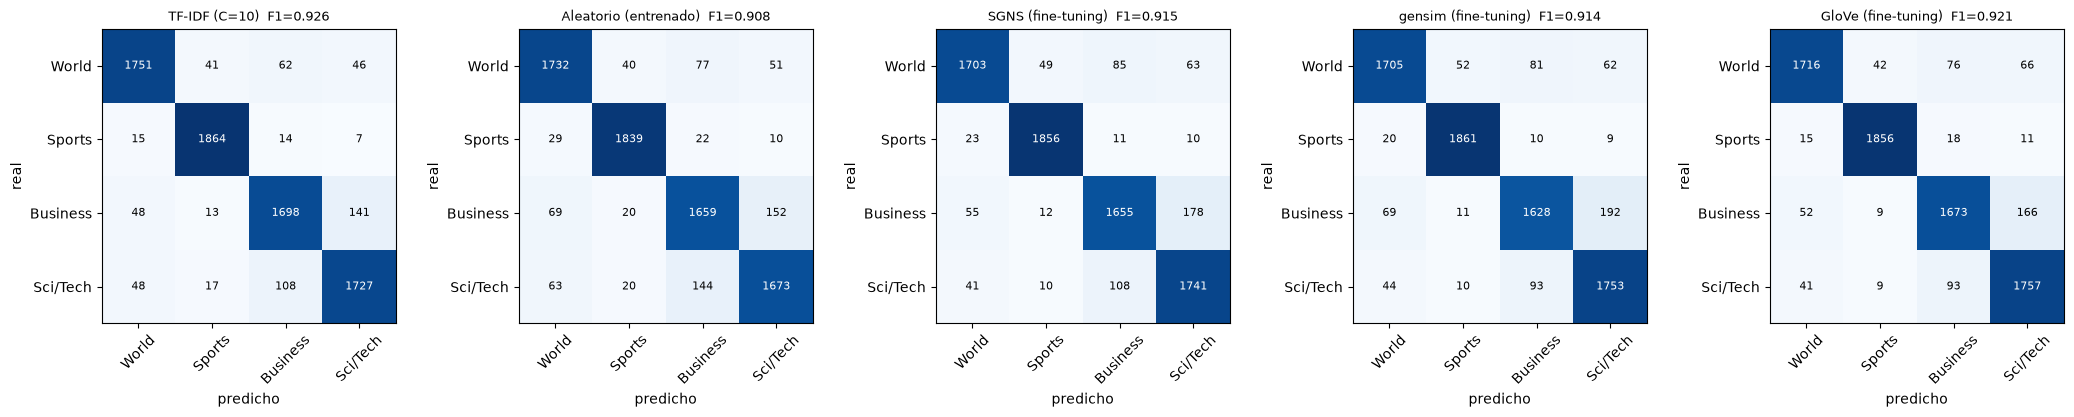

,Spearman SimLex-999,pares evaluados
embedding,,
SGNS,0.294,995/999
gensim,0.316,995/999
GloVe,0.298,999/999


In [37]:
rows = [{"modelo": "TF-IDF + LogReg", "variante": cls[("TF-IDF", 1.0)]["test"]["variant"], **{k: cls[("TF-IDF", 1.0)]["test"][k] for k in ("acc", "precision", "recall", "f1")}}]
for init in ("Aleatorio", "SGNS", "gensim", "GloVe"):
    t = cls[(init, 1.0)]["test"]; rows.append({"modelo": init, "variante": t["variant"], **{k: t[k] for k in ("acc", "precision", "recall", "f1")}})
test_df = pd.DataFrame(rows); display(test_df.style.format({k: "{:.4f}" for k in ("acc", "precision", "recall", "f1")}))

fig, ax = plt.subplots(1, 5, figsize=(21, 4))
names = ["TF-IDF", "Aleatorio", "SGNS", "gensim", "GloVe"]
for a, n in zip(ax, names):
    cm = cls[(n, 1.0)]["test"]["cm"]; a.imshow(cm / cm.sum(1, keepdims=True), cmap="Blues", vmin=0, vmax=1)
    for i in range(4):
        for j in range(4): a.text(j, i, cm[i, j], ha="center", va="center", color="white" if cm[i, j] / cm[i].sum() > .5 else "black", fontsize=8)
    a.set_xticks(range(4)); a.set_xticklabels(LABELS, rotation=45); a.set_yticks(range(4)); a.set_yticklabels(LABELS)
    a.set_title(f"{n} ({cls[(n, 1.0)]['test']['variant']})  F1={cls[(n, 1.0)]['test']['f1']:.3f}", fontsize=9); a.set_xlabel("predicho"); a.set_ylabel("real")
plt.tight_layout(); FIG.mkdir(exist_ok=True); plt.savefig(FIG / "cls_confusion.png", dpi=150); plt.show()

simlex_rows = [{"embedding": n, "Spearman SimLex-999": (r := similarity_eval(ws, E, SIMLEX))["spearman"], "pares evaluados": f"{r['n_eval']}/{r['n_total']}"} for n, (ws, E) in EMBS.items()]
simlex_df = pd.DataFrame(simlex_rows).set_index("embedding"); display(simlex_df.style.format({"Spearman SimLex-999": "{:.3f}"}))

### 6.3 F1 de test vs. fracción de datos de entrenamiento de AG News
Misma metodología para fracciones del train (1 %, 5 %, 10 %, 25 %, 50 %, 100 %; la validación completa se usa para elegir la variante y el test se evalúa una vez por punto).

modelo,Aleatorio,GloVe,SGNS,TF-IDF,gensim
fracción,,,,,
0.010000,0.5146,0.8651,0.8568,0.8120,0.8484
0.050000,0.7971,0.8873,0.8850,0.8793,0.8814
0.100000,0.8434,0.9000,0.8953,0.8927,0.8923
0.250000,0.8778,0.9074,0.9026,0.9088,0.9023
0.500000,0.8922,0.9134,0.9073,0.9146,0.9090
1.000000,0.9082,0.9213,0.9151,0.9262,0.9139


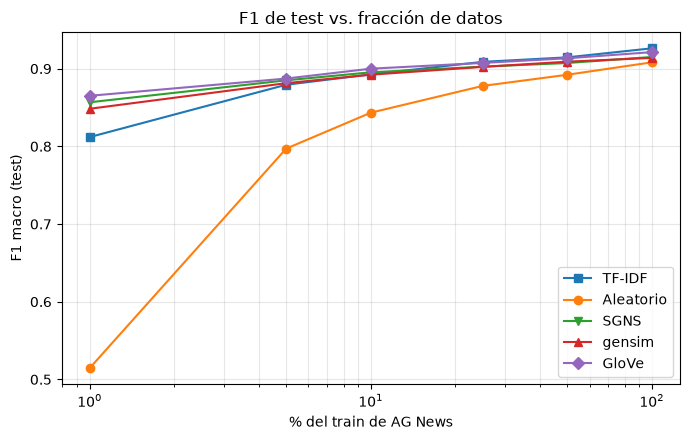

In [38]:
frac_rows = [{"fracción": f, "modelo": n, "variante": cls[(n, f)]["test"]["variant"], "F1 test": cls[(n, f)]["test"]["f1"], "acc test": cls[(n, f)]["test"]["acc"]} for f in FRACS for n in ["TF-IDF", "Aleatorio", "SGNS", "gensim", "GloVe"]]
frac_df = pd.DataFrame(frac_rows); display(frac_df.pivot(index="fracción", columns="modelo", values="F1 test").style.format("{:.4f}"))
plt.figure(figsize=(7, 4.5))
for n, mk in zip(["TF-IDF", "Aleatorio", "SGNS", "gensim", "GloVe"], "sov^D"):
    d = frac_df[frac_df["modelo"] == n]; plt.plot(d["fracción"] * 100, d["F1 test"], marker=mk, label=n)
plt.xscale("log"); plt.xlabel("% del train de AG News"); plt.ylabel("F1 macro (test)"); plt.title("F1 de test vs. fracción de datos"); plt.grid(alpha=.3, which="both"); plt.legend(); plt.tight_layout(); FIG.mkdir(exist_ok=True); plt.savefig(FIG / "f1_vs_fraccion.png", dpi=150); plt.show()

## 7. Comparación de resultados
Tabla comparativa de los tres conjuntos de embeddings y gráficas. Las tablas también se exportan a `informe/*.tex` para incluirlas directamente en el informe de LaTeX.

,tokens,d,"ana total % (vocab. compartido, 3CosAdd)",3CosMul
corrida,,,,
d100_base,"29,604,250",100,47.3,42.7
d50,"29,604,250",50,35.5,29.3
d300,"29,604,250",300,49.1,48.0
frac25,"7,401,084",100,24.3,19.3
frac50,"14,802,159",100,36.1,31.3
W2,"29,604,250",100,44.4,40.3
W10,"29,604,250",100,45.3,41.1
K15,"29,604,250",100,48.8,45.3
t1e-5,"29,604,250",100,41.5,37.2


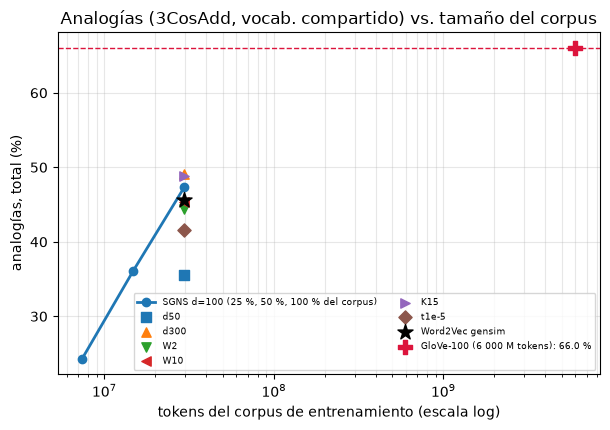

In [39]:
INF = Path("informe"); INF.mkdir(exist_ok=True)

def tex_table(header, rows, colfmt, **_):
    # Genera solo el entorno tabular de LaTeX (booktabs); el informe lo envuelve en su propio float / resizebox.
    esc = lambda s: str(s).replace("_", r"\_").replace("%", r"\%").replace("&", r"\&").replace("≈", r"$\approx$")
    out = [r"\begin{tabular}{" + colfmt + "}", r"\toprule", " & ".join(esc(h) for h in header) + r" \\", r"\midrule"]
    out += [" & ".join(esc(c) for c in r) + r" \\" for r in rows] + [r"\bottomrule", r"\end{tabular}"]
    return chr(10).join(out)

# ---- Todas las corridas SGNS evaluadas sobre el MISMO vocabulario compartido (comparables con GloVe y gensim) ----
run_shared = {}
for name, r in results.items():
    E = np.load(ART / "runs" / f"{name}.npy").astype(np.float32); run_shared[name] = analogy_eval(words, E, allowed=shared, methods=("add", "mul"))
run_shared["gensim_best"] = sysres["gensim"]; glove_ref = sysres["GloVe"]["add"]["total"] * 100
tok_df = pd.DataFrame([{"corrida": n, "tokens": results[n]["config"]["tokens_corpus"], "d": results[n]["config"]["d"], "ana total % (vocab. compartido, 3CosAdd)": run_shared[n]["add"]["total"] * 100,
                        "3CosMul": run_shared[n]["mul"]["total"] * 100} for n in results]).set_index("corrida")
display(tok_df.style.format({"tokens": "{:,}", "ana total % (vocab. compartido, 3CosAdd)": "{:.1f}", "3CosMul": "{:.1f}"}))

fig, ax = plt.subplots(figsize=(6.2, 4.4))
fr = ["frac25", "frac50", "d100_base"]
ax.plot([results[n]["config"]["tokens_corpus"] for n in fr], [run_shared[n]["add"]["total"] * 100 for n in fr], "o-", lw=2, label="SGNS d=100 (25 %, 50 %, 100 % del corpus)")
for n, mk in (("d50", "s"), ("d300", "^"), ("W2", "v"), ("W10", "<"), ("K15", ">"), ("t1e-5", "D")):
    ax.scatter(results[n]["config"]["tokens_corpus"], run_shared[n]["add"]["total"] * 100, marker=mk, s=45, zorder=3, label=n)
ax.scatter(N_TOK, run_shared["gensim_best"]["add"]["total"] * 100, marker="*", s=130, c="k", zorder=4, label="Word2Vec gensim")
ax.scatter(6e9, glove_ref, marker="P", s=110, c="crimson", zorder=4, label=f"GloVe-100 (6 000 M tokens): {glove_ref:.1f} %")
ax.axhline(glove_ref, color="crimson", ls="--", lw=1)
ax.set_xscale("log"); ax.set_xlabel("tokens del corpus de entrenamiento (escala log)"); ax.set_ylabel("analogías, total (%)")
ax.set_title("Analogías (3CosAdd, vocab. compartido) vs. tamaño del corpus"); ax.grid(alpha=.3, which="both")
ax.legend(fontsize=6.5, loc="lower right", ncol=2); plt.tight_layout(); plt.savefig(FIG / "analogias_vs_tokens.png", dpi=150, bbox_inches="tight"); plt.show()

In [40]:
# ---- Tabla comparativa SGNS vs gensim vs GloVe ----
ws_sims = {n: similarity_eval(e.words, e.En, WS353) for n, e in EMB.items()}
sl_sims = {n: similarity_eval(e.words, e.En, SIMLEX) for n, e in EMB.items()}
sgns_train = sum(h["epoch_secs"] for h in results[best_name]["history"]); sgns_ep = sgns_train / len(results[best_name]["history"])
cmp_rows = {
 "Tokens del corpus de entrenamiento": {"SGNS": f"{N_TOK:,}", "gensim": f"{N_TOK:,}", "GloVe": "6 000 000 000"},
 "Tamaño del vocabulario": {n: f"{len(e.words):,}" for n, e in EMB.items()},
 "Dimensión": {n: str(e.En.shape[1]) for n, e in EMB.items()},
 "Tiempo de entrenamiento": {"SGNS": f"{sgns_train/60:.1f} min ({sgns_ep:.0f} s/epoch x {len(results[best_name]['history'])})", "gensim": f"{g_res['train_secs']/60:.1f} min ({g_res['train_secs']/len(g_res['history']):.0f} s/epoch x {len(g_res['history'])})",
                             "GloVe": "matriz X ≈ 85 min (1 hilo) + 50 iteraciones*"},
 "Hardware": {"SGNS": "GPU GTX 1660 SUPER (6 GB)", "gensim": "CPU Ryzen 7 3700X, 8 hilos", "GloVe": "2 x Xeon E5-2658 2.1 GHz, 32 núcleos*"},
 "Analogías semánticas % (3CosAdd / 3CosMul)": {n: f"{sysres[n]['add']['sem']*100:.1f} / {sysres[n]['mul']['sem']*100:.1f}" for n in EMB},
 "Analogías sintácticas % (3CosAdd / 3CosMul)": {n: f"{sysres[n]['add']['syn']*100:.1f} / {sysres[n]['mul']['syn']*100:.1f}" for n in EMB},
 "Analogías total % (3CosAdd / 3CosMul)": {n: f"{sysres[n]['add']['total']*100:.1f} / {sysres[n]['mul']['total']*100:.1f}" for n in EMB},
 "Spearman WordSim-353": {n: f"{ws_sims[n]['spearman']:.3f}" for n in EMB},
 "Spearman SimLex-999": {n: f"{sl_sims[n]['spearman']:.3f}" for n in EMB},
 "Coseno medio entre vectores diferencia (paralelismo)": {n: f"{par[n]['_promedio']:.3f}" for n in EMB},
 "Tokens de AG News fuera del vocabulario %": {n: f"{oov_df.loc[n, 'tokens AG fuera de vocab %']:.2f}" for n in EMB},
 "F1-macro en test de AG News (variante)": {n: f"{cls[(n, 1.0)]['test']['f1']:.4f} ({cls[(n, 1.0)]['test']['variant']})" for n in EMB},
}
cmp_df = pd.DataFrame(cmp_rows).T[["SGNS", "gensim", "GloVe"]]; pd.set_option("display.max_colwidth", 80); display(cmp_df)
print("* GloVe: tiempos reportados por Pennington et al. (2014) para el corpus de 6 000 M de tokens: ≈85 min para construir X con 1 hilo, 14 min/iteración con 300 dim y 32 núcleos; usan 50 iteraciones para dim < 300 (el tiempo por iteración a 100 dim no se reporta).")
print("Evaluación de analogías: vocabulario compartido de 30 000 palabras, %d preguntas (%.1f %% del total)." % (cov["n_eval"], cov["n_eval"] / cov["n_total"] * 100))

(INF / "tabla_comparativa.tex").write_text(tex_table(["Métrica", "SGNS (propio)", "Word2Vec gensim", "GloVe-100"], [[k, *v] for k, v in cmp_df.iterrows()], "p{5.6cm}lll"), encoding="utf-8")

,SGNS,gensim,GloVe
Tokens del corpus de entrenamiento,"29,604,250","29,604,250",6 000 000 000
Tamaño del vocabulario,"100,844","100,844","400,000"
Dimensión,100,100,100
Tiempo de entrenamiento,7.6 min (45 s/epoch x 10),2.9 min (18 s/epoch x 10),matriz X ≈ 85 min (1 hilo) + 50 iteraciones*
Hardware,GPU GTX 1660 SUPER (6 GB),"CPU Ryzen 7 3700X, 8 hilos","2 x Xeon E5-2658 2.1 GHz, 32 núcleos*"
Analogías semánticas % (3CosAdd / 3CosMul),43.3 / 38.0,37.3 / 34.1,60.6 / 58.1
Analogías sintácticas % (3CosAdd / 3CosMul),49.0 / 44.7,49.1 / 45.9,68.3 / 67.0
Analogías total % (3CosAdd / 3CosMul),47.3 / 42.7,45.6 / 42.4,66.0 / 64.4
Spearman WordSim-353,0.689,0.686,0.533
Spearman SimLex-999,0.294,0.316,0.298


* GloVe: tiempos reportados por Pennington et al. (2014) para el corpus de 6 000 M de tokens: ≈85 min para construir X con 1 hilo, 14 min/iteración con 300 dim y 32 núcleos; usan 50 iteraciones para dim < 300 (el tiempo por iteración a 100 dim no se reporta).
Evaluación de analogías: vocabulario compartido de 30 000 palabras, 11611 preguntas (59.4 % del total).


1159

In [41]:
# ---- Tablas auxiliares en LaTeX para el informe (iteraciones y analogías por categoría) ----
it_rows = [[n, f"{r['tokens corpus']/1e6:.1f}", int(r["d"]), int(r["W"]), int(r["K"]), f"{r['t']:g}", f"{r['pérdida final']:.3f}", f"{r['ana sem %']:.1f}", f"{r['ana syn %']:.1f}", f"{r['ana total %']:.1f}", f"{r['WS353 ρ']:.3f}",
            f"{r['t/epoch (s)']:.0f}", f"{r['t total (min)']:.1f}", f"{r['GPU pico (MB)']:.0f}"] for n, r in runs_df.iterrows()]
(INF / "tabla_iteraciones.tex").write_text(tex_table(["Corrida", "Tokens (M)", "d", "W", "K", "t", "Pérdida", "Sem.", "Sin.", "Total", "WS353", "s/ep", "min", "MB GPU"], it_rows, "lrrrrrrrrrrrrr"), encoding="utf-8")
cat_rows = [[c.replace("gram", "g").replace("-", " ") if c in CATS else c, *[f"{sys_df.loc[c, f'{n} {m}']:.1f}" for n in EMB for m in ("3CosAdd", "3CosMul")]] for c in sys_df.index]
(INF / "tabla_categorias.tex").write_text(tex_table(["Categoría", "SGNS add", "SGNS mul", "gensim add", "gensim mul", "GloVe add", "GloVe mul"], cat_rows, "lrrrrrr"), encoding="utf-8")

# ---- Vectores del mejor modelo (formato gensim .kv; se carga con KeyedVectors.load) ----
kv_best = KeyedVectors(sgns_E.shape[1]); kv_best.add_vectors(words, sgns_E); kv_best.save(str(VEC / "sgns_best_d100.kv"))
print("vectores guardados:", VEC / "sgns_best_d100.kv", f"({(VEC / 'sgns_best_d100.kv').stat().st_size / 2**20:.0f} MB) | prueba:", KeyedVectors.load(str(VEC / "sgns_best_d100.kv")).most_similar("king", topn=3))

vectores guardados: vectors\sgns_best_d100.kv (40 MB) | prueba: [('prince', 0.7038790583610535), ('edward', 0.6916337013244629), ('monarch', 0.6856086850166321)]


## 8. Discusión y análisis
*(Todas las cifras provienen de las secciones anteriores; una sola semilla por experimento. En AG News el error estándar de una accuracy ≈ 0.92 sobre 7 600 ejemplos es ≈ 0.3 puntos, así que diferencias menores a ~0.5 puntos no son concluyentes.)*

**1. ¿Se cumple la aritmética vectorial? ¿Dónde funciona y dónde falla?** Se cumple **de forma aproximada y desigual**. En el benchmark completo (vocabulario compartido de 30 000 palabras, 11 611 preguntas) el SGNS acierta 47.3 % (3CosAdd), gensim 45.6 % y GloVe 66.0 %. Funciona mejor en relaciones frecuentes y regulares: *nationality-adjective* (SGNS 83.7 %, GloVe 97.4 %), *capital-common-countries* (71.3 % / 92.9 %), *past-tense* (66.0 %; aquí SGNS supera a GloVe, 58.8 %) y *gram8-plural* (50.6 %). Falla en *currency* (0.0 %: solo 70 de 866 preguntas tienen sus 4 palabras en el vocabulario compartido), *gram2-opposite* (9.2 %), *gram1-adjective-to-adverb* (15.4 %) y *city-in-state* (29.5 %). En las 27 analogías propias el SGNS acierta el 74 % en top-1 y el 89 % en top-5 (GloVe: 81 % y 93 %); los fallos típicos son polisemia (`good:best::bad:?` → *awards, nominated*, por el uso de "best" en premios) y entidades poco frecuentes (`japan:tokyo::italy:?` → *paris*, rango 7). **Semántica vs. sintaxis:** en los tres modelos las sintácticas salen más altas (SGNS 49.0 vs 43.3 %; GloVe 68.3 vs 60.6 %), pero el grupo semántico contiene las categorías más difíciles (*currency*, *city-in-state*); además la dimensión importa distinto: con d = 300 el SGNS sube a 56.7 % en semánticas pero baja a 45.9 % en sintácticas.

**2. ¿Es el «≈» de king − man + woman ≈ queen una igualdad?** No. (i) **Sin excluir las palabras de la consulta**, el primer lugar es la propia palabra *c* en el 48 % de las analogías del SGNS (44 % gensim, 33 % GloVe) y *b* en 26 % (22 % / 11 %); solo en 22 % (SGNS), 30 % (gensim) y 48 % (GloVe) es la respuesta correcta. Para `man:woman::king:?` los tres modelos devuelven *king* (0.77, 0.77, 0.84) y luego *queen* (0.72, 0.70, 0.77): el vector resultante queda **cerca de king**, y *queen* es el vecino más cercano solo después de excluir la consulta. (ii) El coseno medio entre el vector resultante y la respuesta correcta es 0.69 (SGNS), 0.70 (gensim) y 0.83 (GloVe), lejos de 1. (iii) **Paralelismo:** el coseno medio entre vectores diferencia de pares de una misma relación es 0.226 (SGNS), 0.243 (gensim) y 0.406 (GloVe), frente a ≈ 0.00 para pares aleatorios; es decir, las diferencias comparten una dirección (más en *nationality-adjective*: 0.45 / 0.48 / 0.75) pero lejos de ser el mismo vector (igualdad exacta daría 1). El «≈» significa «la respuesta correcta está entre los vecinos más cercanos de un vector que apunta aproximadamente en la dirección de la relación».

**3. ¿Qué tan lejos quedó GloVe?** −18.7 puntos en analogías totales con 3CosAdd (47.3 vs 66.0 %), pero **no** en similitud: WordSim-353 0.689 vs 0.533 y SimLex-999 0.294 vs 0.298 (empate). *Corpus vs. método:* GloVe usó 6 000 M de tokens (≈ 203× los 29.6 M nuestros), con otro dominio (Wikipedia 2014 + Gigaword), ventana de 10 y 50 iteraciones. El Word2Vec de gensim con **nuestro** corpus obtiene prácticamente lo mismo que nuestro SGNS (45.6 %), así que la diferencia no se debe a nuestra implementación. El experimento de tamaño de corpus muestra que el corpus pesa mucho y que aún no se satura: 25 % → 50 % → 100 % da 24.3 → 36.1 → 47.3 % (**≈ +11.5 puntos por duplicación**). WikiText-103 completo (97.5 M de tokens) serían ≈ 1.7 duplicaciones más (≈ +20 puntos por extrapolación lineal, que sobreestima por los rendimientos decrecientes), cifra del orden de la brecha con GloVe. Por tanto **la mayor parte de la diferencia es razonablemente atribuible al tamaño del corpus**, pero no podemos separar con exactitud la parte debida al método (conteos globales de GloVe) o a sus hiperparámetros, porque no entrenamos GloVe sobre nuestro corpus. Salvedad: el vocabulario compartido se ordena por la frecuencia en *nuestro* corpus, lo que puede favorecer algo a nuestros modelos.

**4. ¿Se comporta nuestro SGNS como el de gensim?** Sí: analogías totales 47.3 vs 45.6 % (3CosAdd) y 42.7 vs 42.4 % (3CosMul), sintácticas 49.0 vs 49.1 %, WordSim 0.689 vs 0.686, SimLex 0.294 vs 0.316 y vecinos de control similares. La diferencia más notable es semántica (43.3 vs 37.3 %). Posibles causas: (a) el **optimizador** (SparseAdam con batch de 16 384 y decaimiento lineal de la tasa vs. SGD por par con Hogwild, tasa 0.025 → 0.0001); (b) inicialización y tablas de negativos distintas; (c) **sesgo de selección**: la configuración se eligió entre 9 corridas con las mismas métricas con las que se compara, mientras gensim la recibió sin ajuste; (d) una sola semilla. En eficiencia, gensim en CPU (8 hilos) tardó 2.9 min frente a 7.6 min del SGNS en GPU.

**5. Efecto de dimensión, ventana y negativos.** *Dimensión:* 50 → 100 → 300 da analogías totales 35.5 → 47.3 → 49.1 % (rendimientos decrecientes), WS-353 0.647 → 0.689 → 0.668 y tiempo 5.0 → 7.6 → 18.3 min; d = 300 gana en semántica (56.7 %) y pierde en sintaxis y similitud. *Ventana:* con `W = 2` las analogías semánticas son 36.8 % y las sintácticas 47.6 % (brecha de 10.8 puntos); con `W = 5` 43.3 / 49.0 % (5.7); con `W = 10` 43.1 / 46.2 % (3.1): **las ventanas pequeñas favorecen la sintaxis (relativamente) y las grandes la semántica**; `W = 10` cuesta ≈ 1.8× más tiempo que `W = 5`. *Negativos:* `K = 15` mejora las analogías (48.8 vs 47.3 %; sobre todo semánticas: 48.8 vs 43.3 %) pero empeora WS-353 (0.671 vs 0.689) y cuesta 1.7× más tiempo. *Submuestreo:* `t = 1e-5` descarta demasiado (41.5 % de analogías). *Corpus:* ver punto 3.

**6. AG News: ¿superaron los preentrenados a los aleatorios y a TF-IDF? ¿Congelar o hacer fine-tuning?** Con el 100 % del train y fine-tuning, F1 de test: **TF-IDF 0.926**, GloVe 0.921, SGNS 0.915, gensim 0.914, aleatorio 0.908. Los preentrenados superan a los aleatorios (+1.3 puntos GloVe, +0.7 SGNS), pero **no a TF-IDF** con todos los datos (−0.5 puntos GloVe; TF-IDF usa 1.7 M de rasgos con bigramas, mientras que el promedio de embeddings pierde el orden). Con pocos datos cambia: con el **1 %** (1 080 noticias) GloVe llega a 0.865, SGNS 0.857 y gensim 0.848, contra 0.812 de TF-IDF y **0.515** del aleatorio (+35 puntos); a 5–10 % GloVe y SGNS aún superan a TF-IDF (hasta +0.8), y desde ≈ 25 % TF-IDF empata o gana. **Congelar convino con muy pocos datos**: con el 1 % la variante congelada ganó en validación para los tres (p. ej. GloVe 0.872 vs 0.854 con fine-tuning; el fine-tuning sobreajusta una tabla de 10–40 M de parámetros con 1 080 ejemplos); desde el 5 % el **fine-tuning** gana, y con el 100 % por +1.2 puntos (GloVe: 0.925 vs 0.913) a +2.1 (SGNS: 0.919 vs 0.898) en validación. Una tabla GloVe congelada (27 k parámetros entrenables) iguala a una tabla aleatoria entrenada (4.8 M): 0.913 vs 0.913 en validación. El vocabulario también importa: el 3.12 % de los tokens de AG News queda fuera del vocabulario de SGNS/gensim frente al 0.88 % de GloVe.

**Limitaciones.** Una sola semilla; subconjunto de 29.6 M de los 97.5 M de tokens de WikiText-103; búsqueda de hiperparámetros limitada (9 corridas, una variable a la vez); selección de configuración con analogías y WordSim-353 (SimLex-999 reservado y usado solo al final); el vocabulario compartido (30 000 palabras) cubre el 59.4 % de las preguntas de analogías.